In [1]:
import psycopg
import pandas as pd

# Avacon

In [2]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

# Verluste pro 10-min-Intervall aggregieren (über alle Anlagen)
query = """
    SELECT 
        timestamp,
        SUM(verlust) AS verlust_kwh
    FROM dwd.wind_avacon_2025_interpolated
    GROUP BY timestamp
    ORDER BY timestamp
"""
df = pd.read_sql(query, conn)
conn.close()

C:\Users\user\AppData\Local\Temp\ipykernel_30188\873713238.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


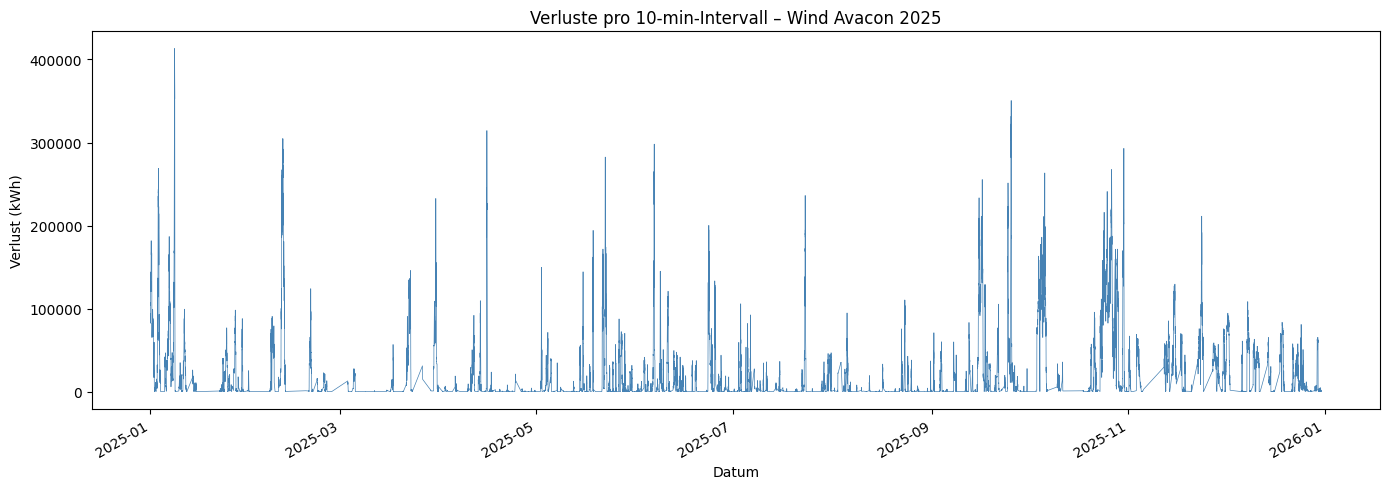

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["timestamp"], df["verlust_kwh"], linewidth=0.5, color="steelblue")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Verluste pro 10-min-Intervall – Wind Avacon 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

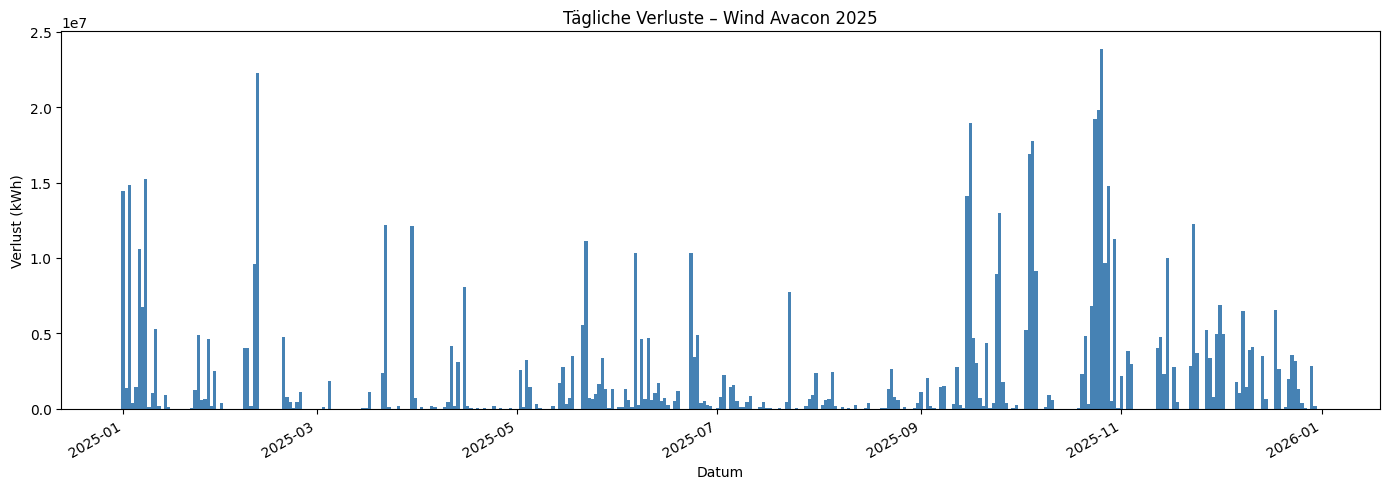

In [4]:
df_daily = df.groupby(df["timestamp"].dt.date)["verlust_kwh"].sum().reset_index()
df_daily.columns = ["tag", "verlust_kwh"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_daily["tag"], df_daily["verlust_kwh"], width=1, color="steelblue")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Tägliche Verluste – Wind Avacon 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [18]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query = """
    SELECT 
        timestamp,
        SUM(verlust) AS verlust_kwh
    FROM dwd.solar_avacon_2025_interpolated
    GROUP BY timestamp
    ORDER BY timestamp
"""
df_solar = pd.read_sql(query, conn)
conn.close()

C:\Users\user\AppData\Local\Temp\ipykernel_31532\1543972340.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_solar = pd.read_sql(query, conn)


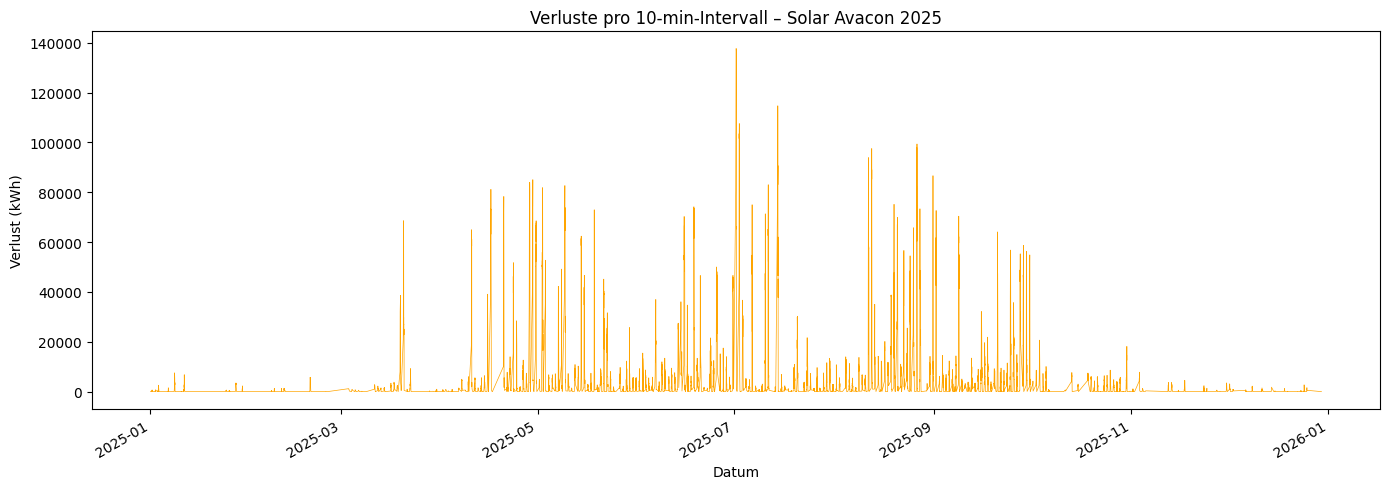

In [19]:
# 10-min-Intervall
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_solar["timestamp"], df_solar["verlust_kwh"], linewidth=0.5, color="orange")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Verluste pro 10-min-Intervall – Solar Avacon 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

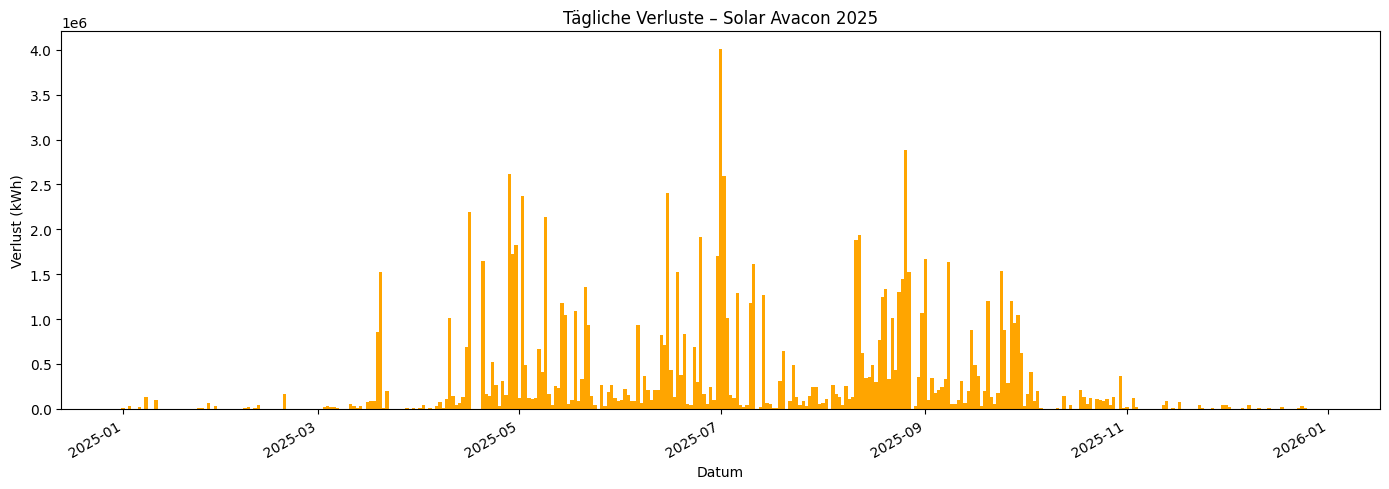

In [20]:
# Täglich
df_solar_daily = df_solar.groupby(df_solar["timestamp"].dt.date)["verlust_kwh"].sum().reset_index()
df_solar_daily.columns = ["tag", "verlust_kwh"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_solar_daily["tag"], df_solar_daily["verlust_kwh"], width=1, color="orange")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Tägliche Verluste – Solar Avacon 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

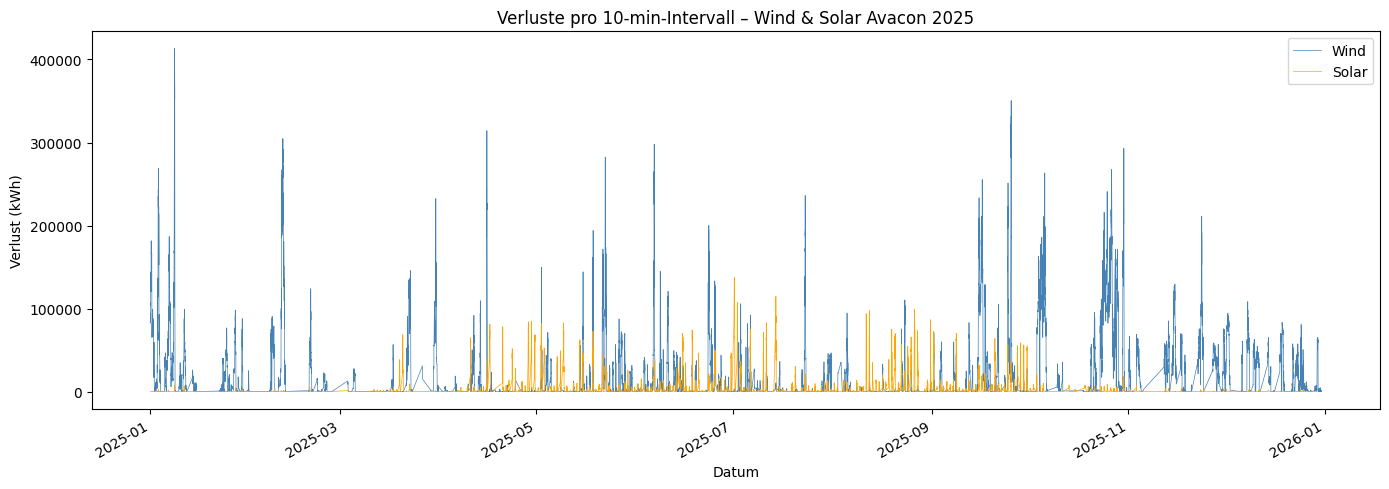

In [27]:
# Kombiniert: Wind + Solar Avacon (10-min)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["timestamp"], df["verlust_kwh"], linewidth=0.5, color="steelblue", label="Wind")
ax.plot(df_solar["timestamp"], df_solar["verlust_kwh"], linewidth=0.5, color="orange", label="Solar")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Verluste pro 10-min-Intervall – Wind & Solar Avacon 2025")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

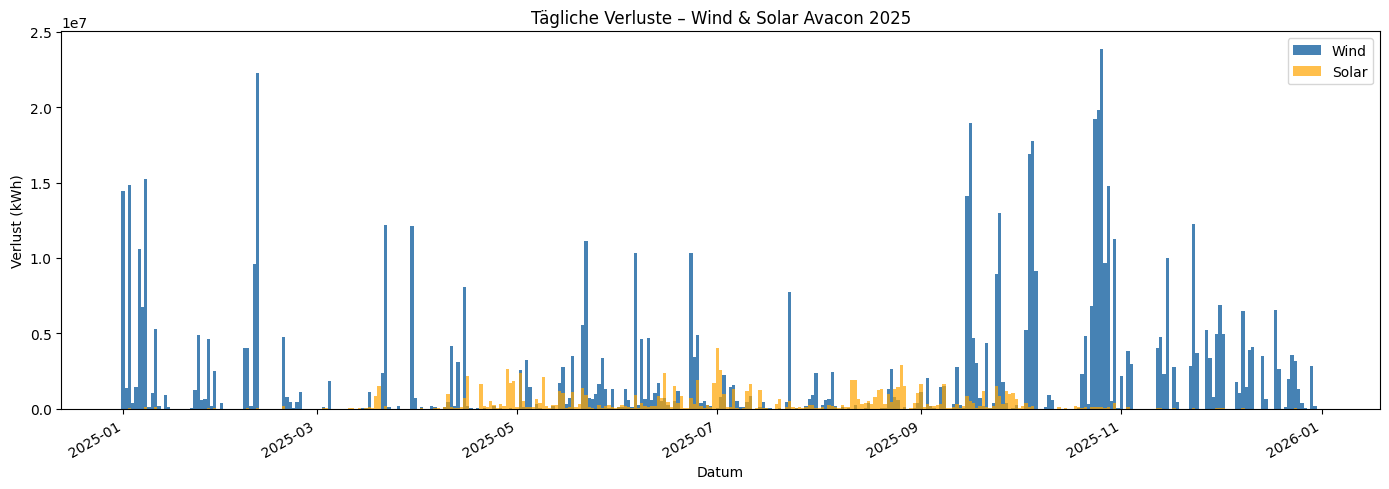

In [28]:
# Kombiniert: Wind + Solar Avacon (täglich)
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_daily["tag"], df_daily["verlust_kwh"], width=1, color="steelblue", label="Wind")
ax.bar(df_solar_daily["tag"], df_solar_daily["verlust_kwh"], width=1, color="orange", alpha=0.7, label="Solar")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Tägliche Verluste – Wind & Solar Avacon 2025")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Bayernwerk


In [15]:
# Wind Bayernwerk laden
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query = """
    SELECT 
        timestamp,
        SUM(verlust) AS verlust_kwh
    FROM dwd.wind_bayernwerk_2025_interpolated
    GROUP BY timestamp
    ORDER BY timestamp
"""
df_bw_wind = pd.read_sql(query, conn)
conn.close()

C:\Users\user\AppData\Local\Temp\ipykernel_30188\652746396.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_bw_wind = pd.read_sql(query, conn)


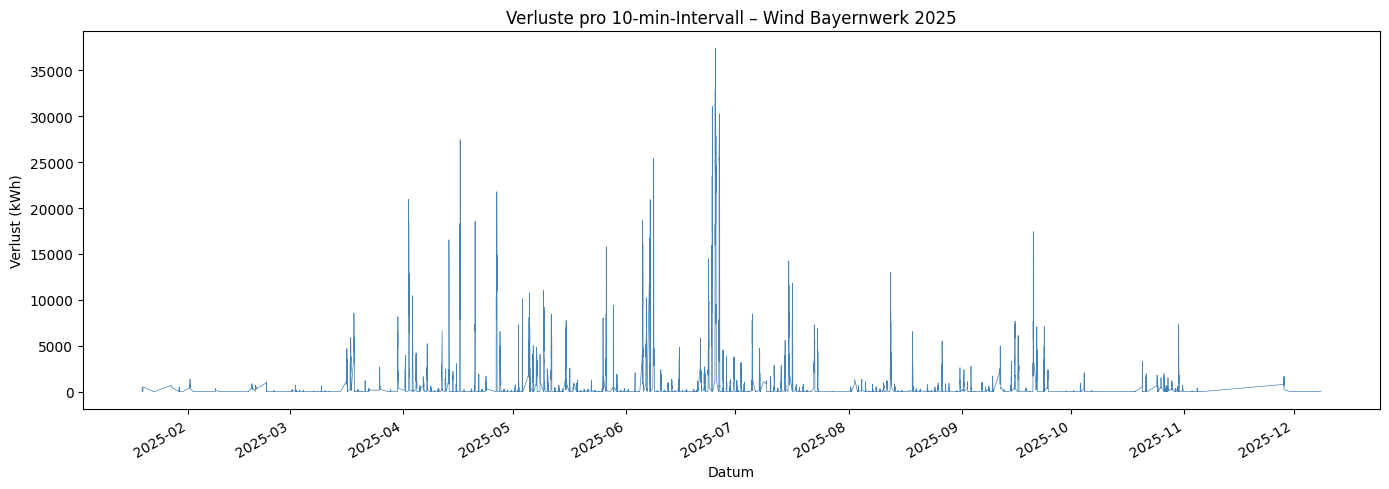

In [16]:
# 10-min-Intervall Wind Bayernwerk
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_bw_wind["timestamp"], df_bw_wind["verlust_kwh"], linewidth=0.5, color="steelblue")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Verluste pro 10-min-Intervall – Wind Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

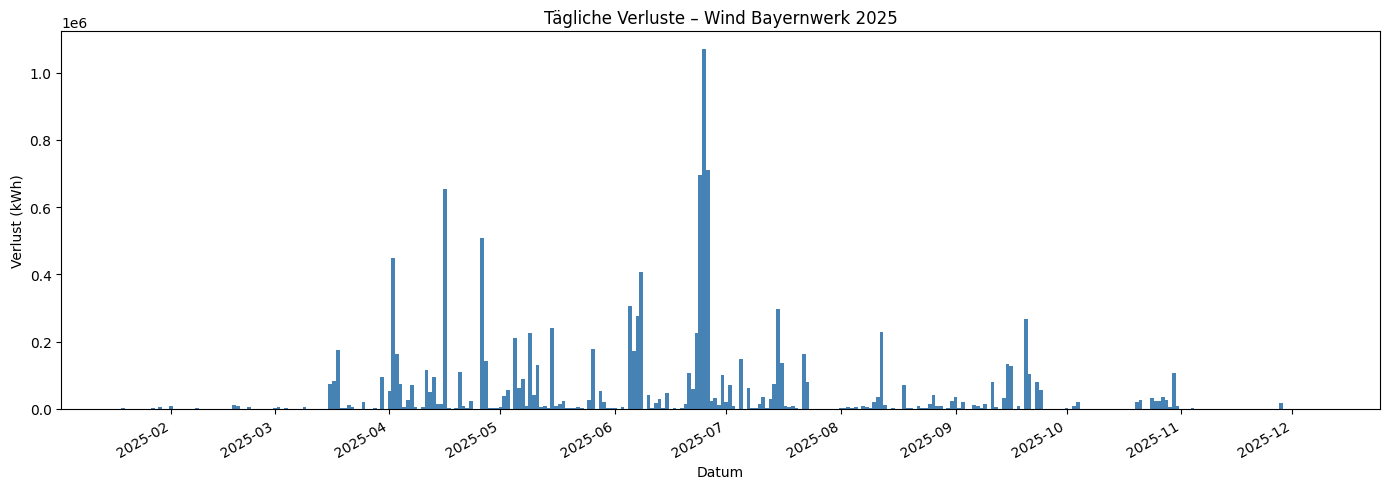

In [17]:
# Täglich Wind Bayernwerk
df_bw_wind_daily = df_bw_wind.groupby(df_bw_wind["timestamp"].dt.date)["verlust_kwh"].sum().reset_index()
df_bw_wind_daily.columns = ["tag", "verlust_kwh"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_bw_wind_daily["tag"], df_bw_wind_daily["verlust_kwh"], width=1, color="steelblue")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Tägliche Verluste – Wind Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [18]:
# Solar Bayernwerk laden
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

query = """
    SELECT 
        timestamp,
        SUM(verlust) AS verlust_kwh
    FROM dwd.solar_bayernwerk_2025_interpolated
    GROUP BY timestamp
    ORDER BY timestamp
"""
df_bw_solar = pd.read_sql(query, conn)
conn.close()

C:\Users\user\AppData\Local\Temp\ipykernel_30188\659362292.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_bw_solar = pd.read_sql(query, conn)


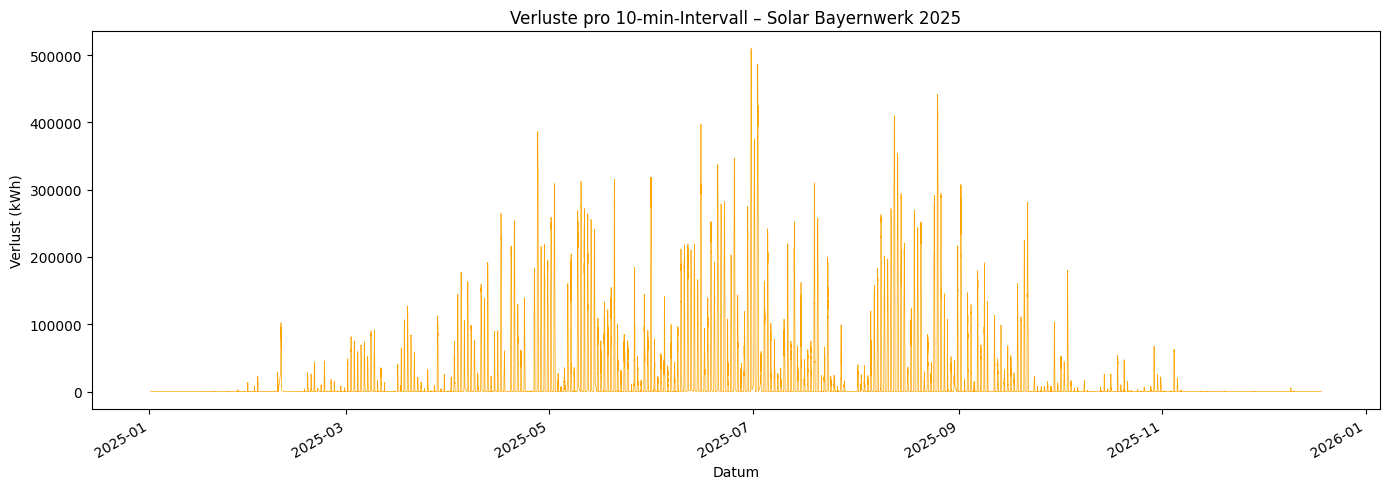

In [19]:
# 10-min-Intervall Solar Bayernwerk
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_bw_solar["timestamp"], df_bw_solar["verlust_kwh"], linewidth=0.5, color="orange")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Verluste pro 10-min-Intervall – Solar Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

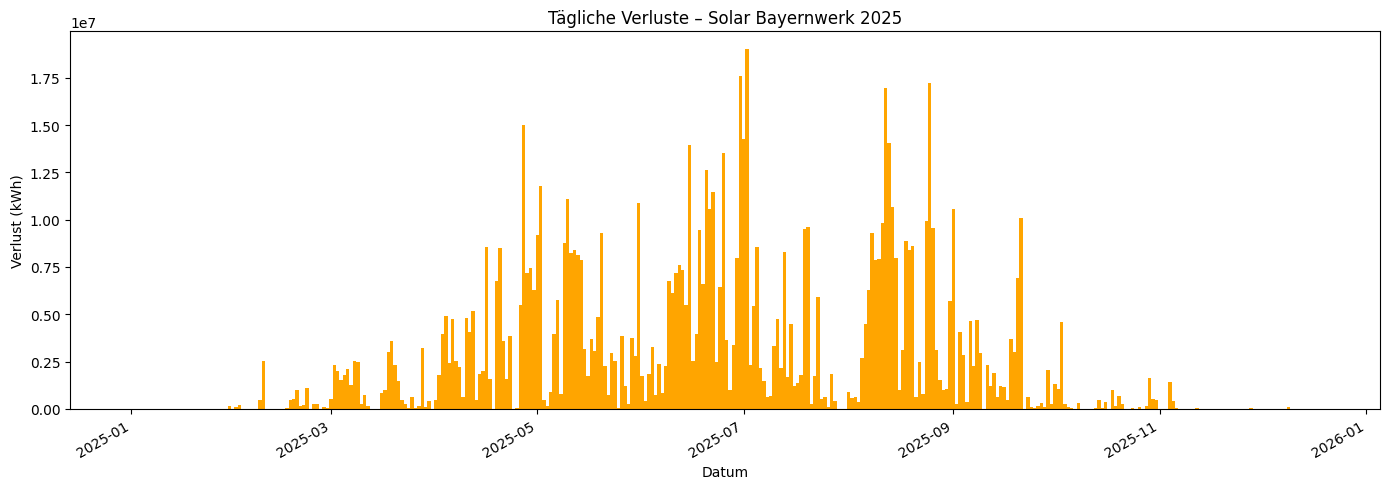

In [20]:
# Täglich Solar Bayernwerk
df_bw_solar_daily = df_bw_solar.groupby(df_bw_solar["timestamp"].dt.date)["verlust_kwh"].sum().reset_index()
df_bw_solar_daily.columns = ["tag", "verlust_kwh"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_bw_solar_daily["tag"], df_bw_solar_daily["verlust_kwh"], width=1, color="orange")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Tägliche Verluste – Solar Bayernwerk 2025")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

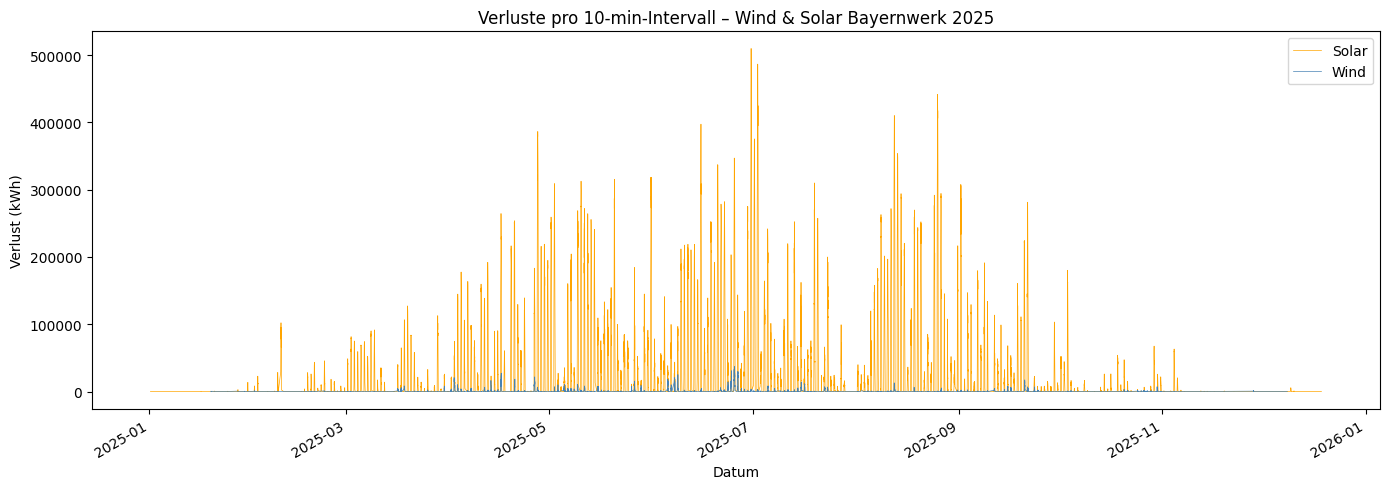

In [22]:
# Kombiniert: Wind + Solar Bayernwerk (10-min)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_bw_solar["timestamp"], df_bw_solar["verlust_kwh"], linewidth=0.5, color="orange", label="Solar")
ax.plot(df_bw_wind["timestamp"], df_bw_wind["verlust_kwh"], linewidth=0.5, color="steelblue", label="Wind")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Verluste pro 10-min-Intervall – Wind & Solar Bayernwerk 2025")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

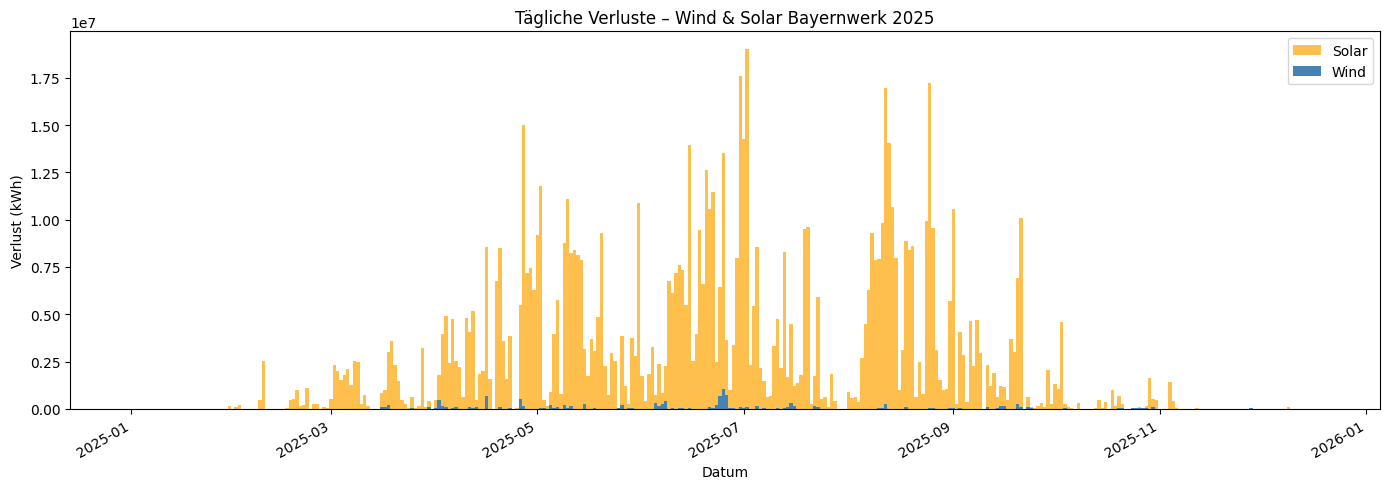

In [24]:
# Kombiniert: Wind + Solar Bayernwerk (täglich)
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df_bw_solar_daily["tag"], df_bw_solar_daily["verlust_kwh"], width=1, color="orange", alpha=0.7, label="Solar")
ax.bar(df_bw_wind_daily["tag"], df_bw_wind_daily["verlust_kwh"], width=1, color="steelblue", label="Wind")
ax.set_xlabel("Datum")
ax.set_ylabel("Verlust (kWh)")
ax.set_title("Tägliche Verluste – Wind & Solar Bayernwerk 2025")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Netzanschluss mit größtem Verlust

In [30]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

# Verlust pro Netzanschluss direkt aus den Redispatch-Tabellen
queries = {
    "Avacon": "redispatch.redispatch_eeg_avacon",
    "Bayernwerk": "redispatch.redispatch_eeg_bayernwerk",
}

results = []
for label, table in queries.items():
    query = f"""
        SELECT 
            netzanschluss,
            SUM(verlust) AS verlust_kwh_gesamt
        FROM {table}
        WHERE verlust IS NOT NULL
        GROUP BY netzanschluss
        ORDER BY verlust_kwh_gesamt DESC
        LIMIT 10
    """
    df_na = pd.read_sql(query, conn)
    df_na["quelle"] = label
    results.append(df_na)

conn.close()

df_netzanschluss = pd.concat(results, ignore_index=True)
df_netzanschluss

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1297457087.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn)
C:\Users\user\AppData\Local\Temp\ipykernel_30188\1297457087.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn)


,netzanschluss,verlust_kwh_gesamt,quelle
0,SEL969510082602,5.732186e+07,Avacon
1,SEL984760148281,4.220456e+07,Avacon
2,SEL959245178619,3.778629e+07,Avacon
3,SEL956189055952,2.569174e+07,Avacon
4,SEL953043138455,2.385627e+07,Avacon
5,SEL925428728391,2.290886e+07,Avacon
6,SEL971466313327,2.104029e+07,Avacon
7,SEL963906694301,2.032157e+07,Avacon
8,SEL984454587501,1.833797e+07,Avacon
9,SEL948059540996,1.746271e+07,Avacon


In [1]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

netzanschluss = "SEL965650034839"

# Wind + Solar Abregelung für diesen Netzanschluss
dfs = {}
for label, rd_table in [("Avacon", "redispatch.redispatch_eeg_avacon"),
                         ("Bayernwerk", "redispatch.redispatch_eeg_bayernwerk")]:
    for typ in ["wind", "solar"]:
        dwd_table = f"dwd.{typ}_{label.lower()}_2025_interpolated"
        query = f"""
            SELECT 
                d.timestamp,
                SUM(d.abregelung) AS abregelung_kwh
            FROM {dwd_table} d
            JOIN {rd_table} r ON d.eventnummer = r.eventnummer
            WHERE r.netzanschluss = %s
            GROUP BY d.timestamp
            ORDER BY d.timestamp
        """
        df_na = pd.read_sql(query, conn, params=(netzanschluss,))
        if not df_na.empty:
            dfs[f"{typ.title()} {label}"] = df_na

conn.close()
# Täglich für SEL987958667335
for key, df_na in dfs.items():
    df_na_daily = df_na.groupby(df_na["timestamp"].dt.date)["abregelung_kwh"].sum().reset_index()
    df_na_daily.columns = ["tag", "abregelung_kwh"]

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(df_na_daily["tag"], df_na_daily["abregelung_kwh"], width=1, color="crimson")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Abregelung (kWh)")
    ax.set_title(f"Tägliche Abregelung – {netzanschluss} ({key}) 2025")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

NameError: name 'psycopg' is not defined

C:\Users\user\AppData\Local\Temp\ipykernel_30188\3940721752.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


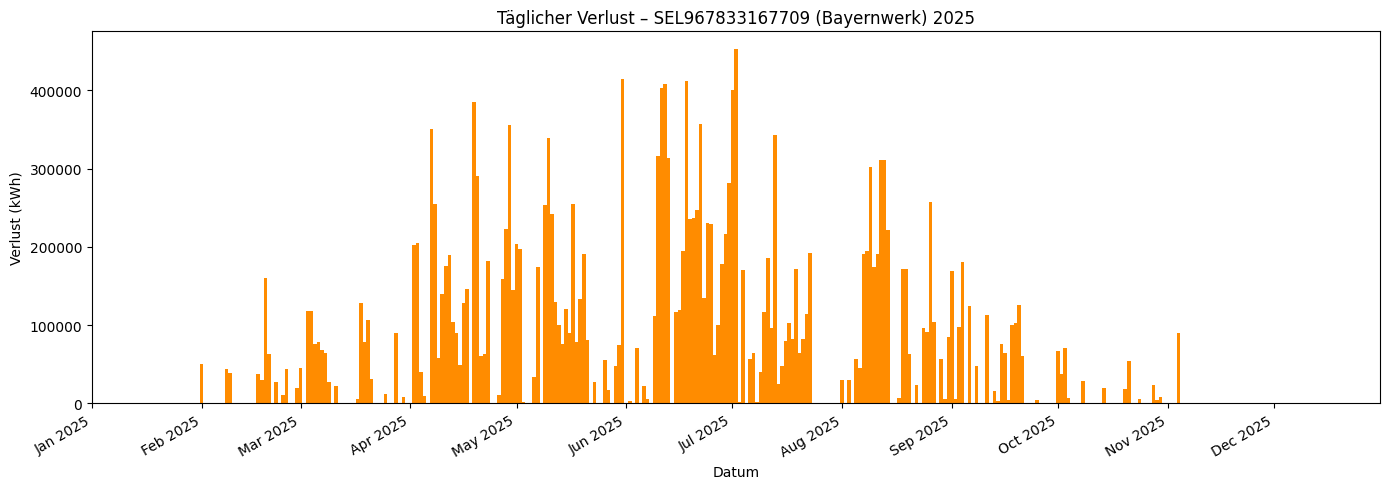

C:\Users\user\AppData\Local\Temp\ipykernel_30188\3940721752.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


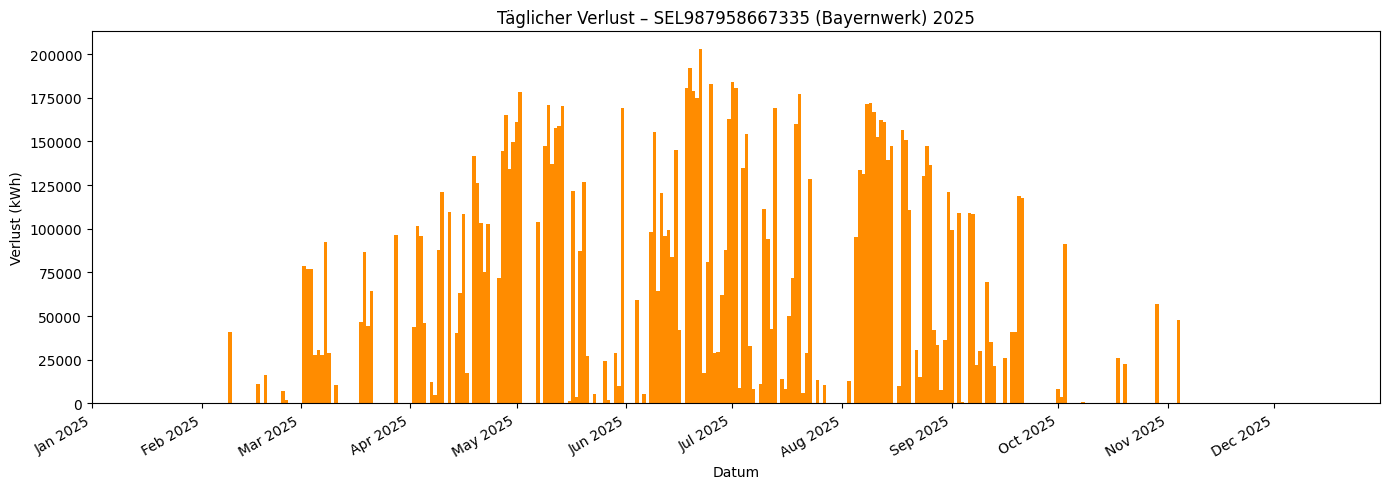

C:\Users\user\AppData\Local\Temp\ipykernel_30188\3940721752.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


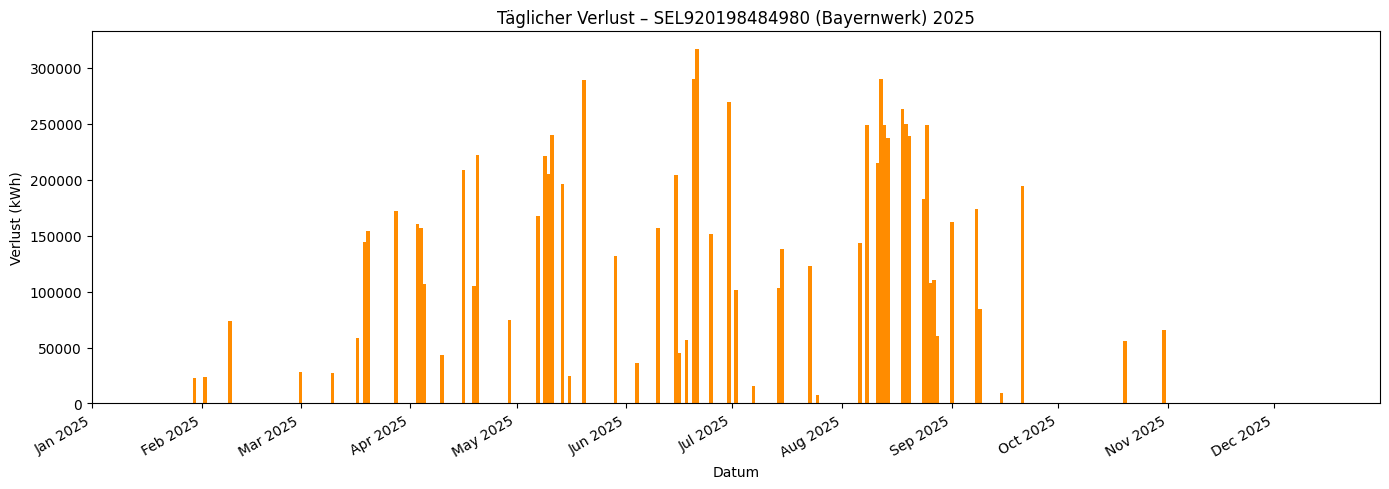

In [39]:
import matplotlib.dates as mdates
from datetime import datetime

conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

netzanschluesse = ["SEL967833167709", "SEL987958667335", "SEL920198484980"]

start = datetime(2025, 1, 1)
end = datetime(2025, 12, 31)

for netzanschluss in netzanschluesse:
    query = """
        SELECT 
            DATE(star) AS tag,
            SUM(verlust) AS verlust_kwh
        FROM redispatch.redispatch_eeg_bayernwerk
        WHERE netzanschluss = %s
          AND verlust IS NOT NULL
        GROUP BY DATE(star)
        ORDER BY DATE(star)
    """
    df_daily = pd.read_sql(query, conn, params=(netzanschluss,))

    if df_daily.empty:
        print(f"Keine Daten für {netzanschluss}")
        continue

    df_daily["tag"] = pd.to_datetime(df_daily["tag"])
    df_daily = df_daily.set_index("tag")
    # Reindex auf kompletten Zeitraum
    idx = pd.date_range(start, end, freq="D")
    df_daily = df_daily.reindex(idx, fill_value=0)
    df_daily = df_daily.reset_index().rename(columns={"index": "tag"})

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(df_daily["tag"], df_daily["verlust_kwh"], width=1, color="darkorange")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Verlust (kWh)")
    ax.set_title(f"Täglicher Verlust – {netzanschluss} (Bayernwerk) 2025")
    ax.set_xlim([start, end])
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

conn.close()

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:25: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top = pd.read_sql(query_top, conn)
C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


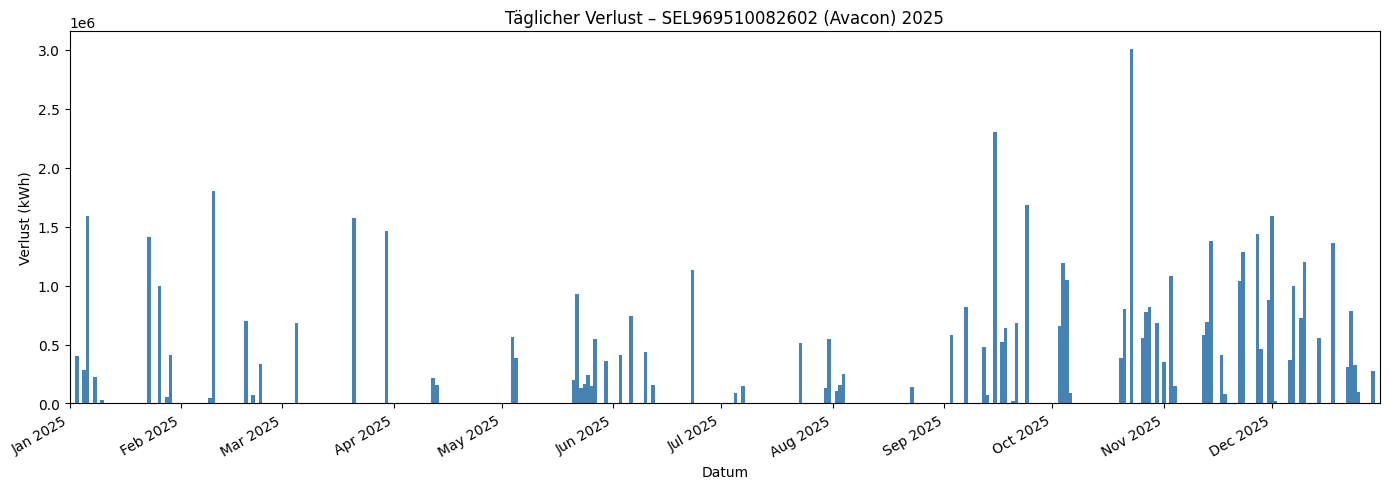

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


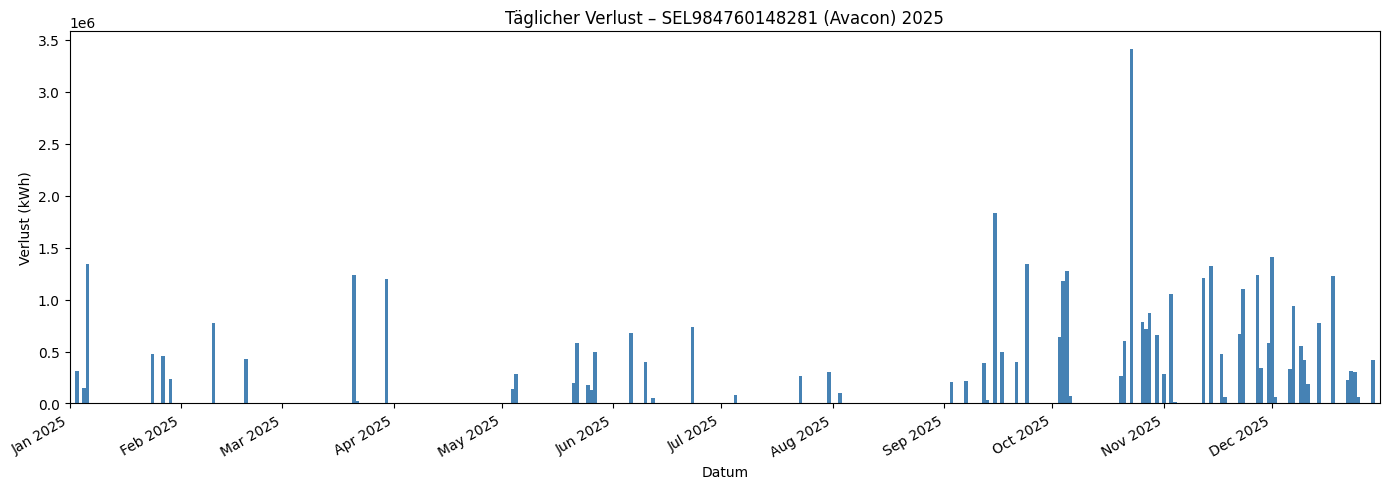

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


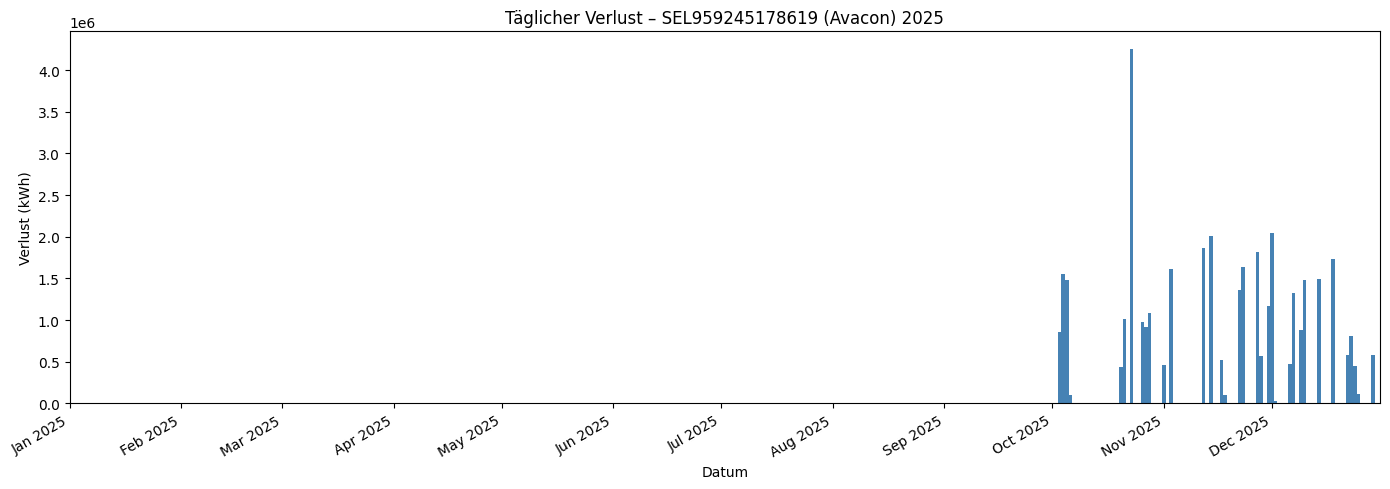

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


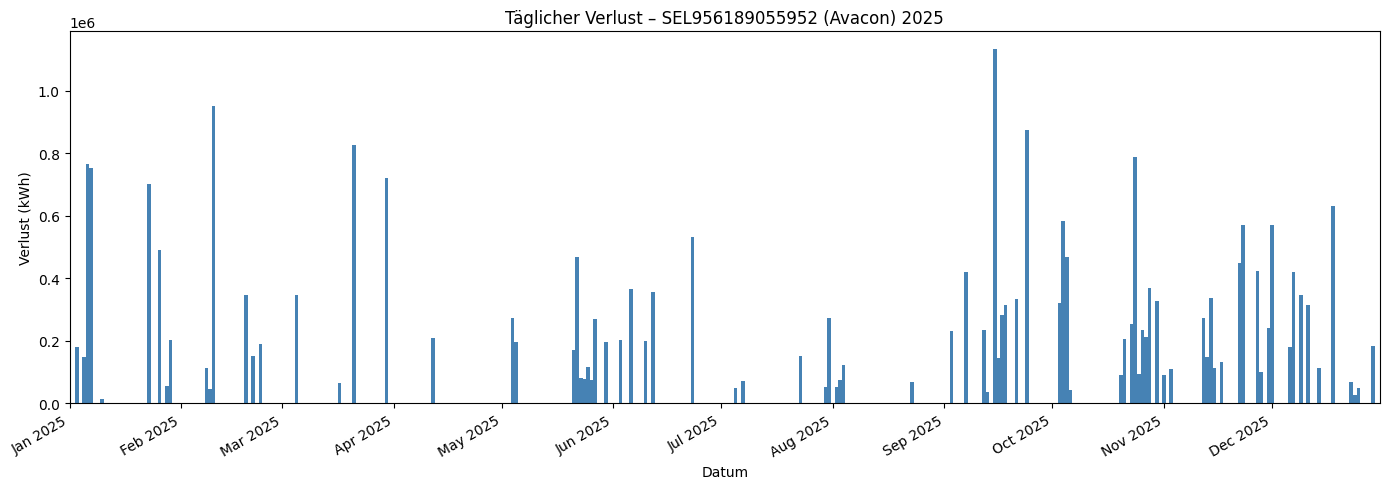

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


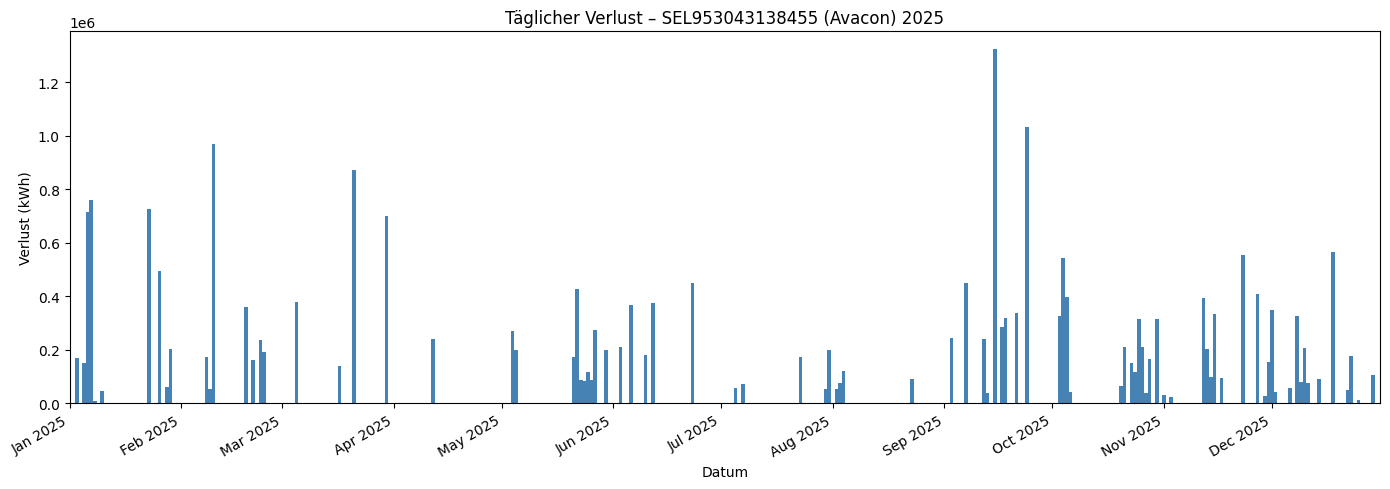

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


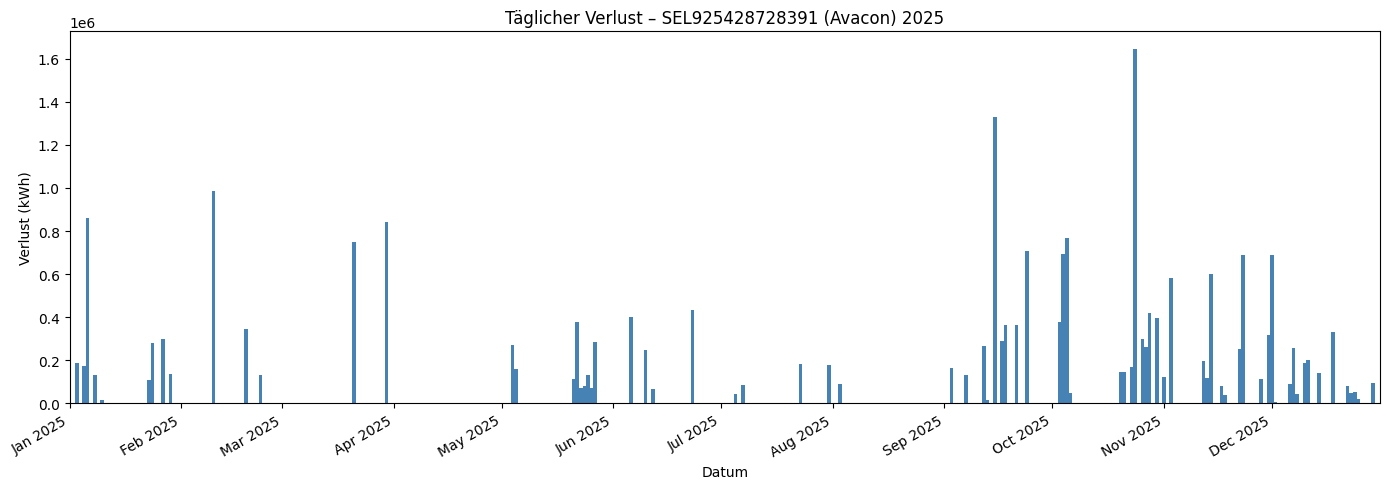

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


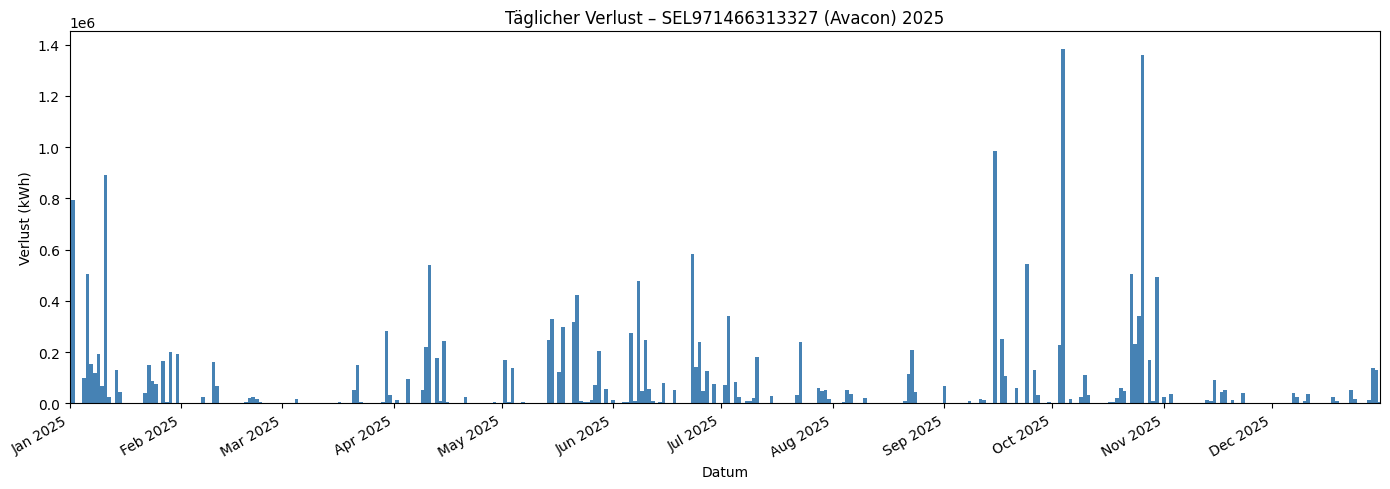

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


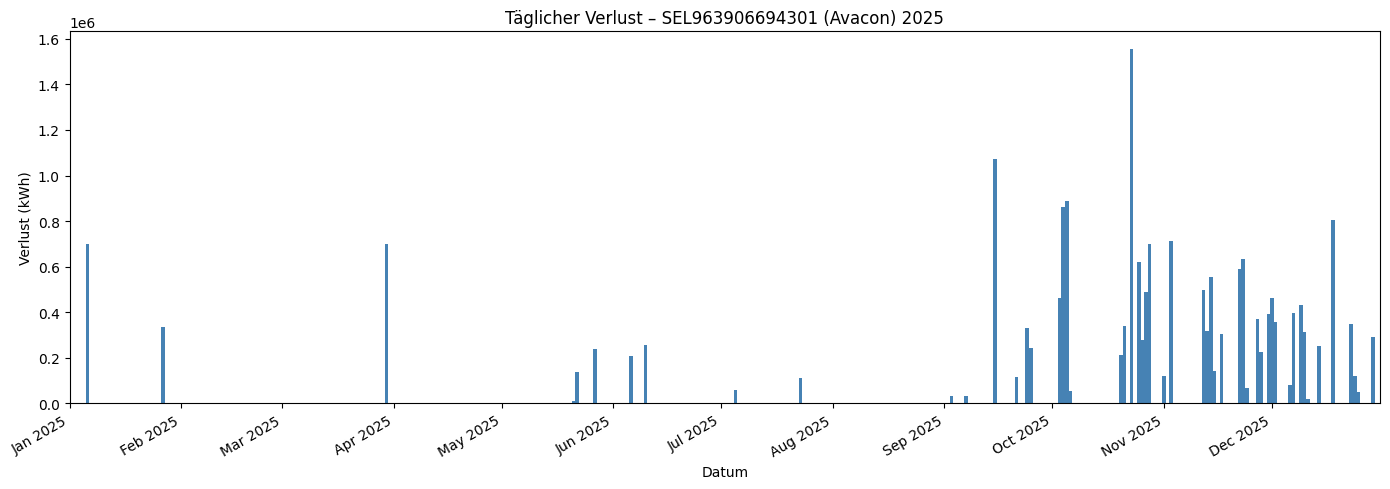

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


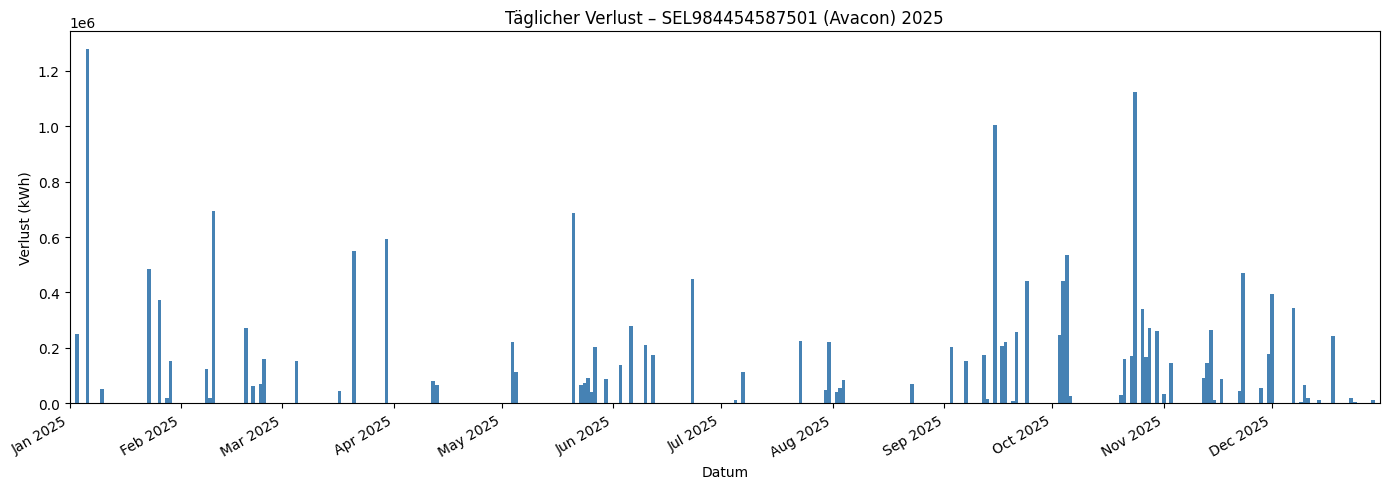

C:\Users\user\AppData\Local\Temp\ipykernel_30188\1464414454.py:42: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_daily = pd.read_sql(query, conn, params=(netzanschluss,))


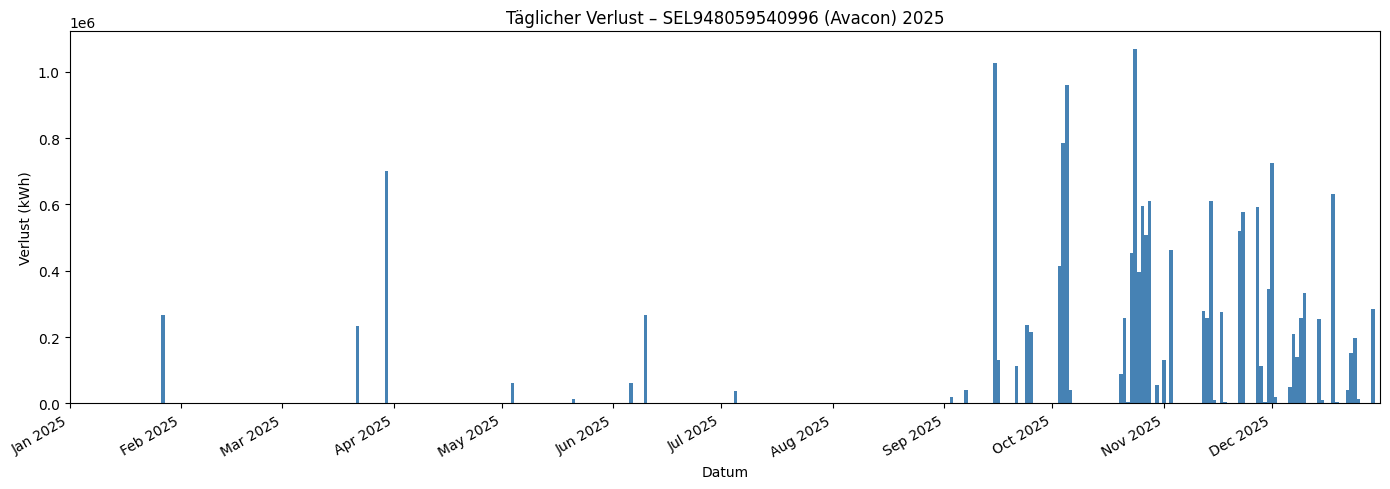

In [41]:
import matplotlib.dates as mdates
from datetime import datetime

conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

# Top 10 Avacon Netzanschlüsse nach Verlust
query_top = """
    SELECT
        netzanschluss,
        SUM(verlust) AS verlust_kwh_gesamt
    FROM redispatch.redispatch_eeg_avacon
    WHERE verlust IS NOT NULL
      AND netzanschluss IS NOT NULL
    GROUP BY netzanschluss
    ORDER BY verlust_kwh_gesamt DESC
    LIMIT 10
"""
df_top = pd.read_sql(query_top, conn)
netzanschluesse = df_top["netzanschluss"].tolist()

start = datetime(2025, 1, 1)
end = datetime(2025, 12, 31)

for netzanschluss in netzanschluesse:
    query = """
        SELECT 
            DATE(star) AS tag,
            SUM(verlust) AS verlust_kwh
        FROM redispatch.redispatch_eeg_avacon
        WHERE netzanschluss = %s
          AND verlust IS NOT NULL
        GROUP BY DATE(star)
        ORDER BY DATE(star)
    """
    df_daily = pd.read_sql(query, conn, params=(netzanschluss,))

    if df_daily.empty:
        print(f"Keine Daten für {netzanschluss}")
        continue

    df_daily["tag"] = pd.to_datetime(df_daily["tag"])
    df_daily = df_daily.set_index("tag")
    idx = pd.date_range(start, end, freq="D")
    df_daily = df_daily.reindex(idx, fill_value=0)
    df_daily = df_daily.reset_index().rename(columns={"index": "tag"})

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(df_daily["tag"], df_daily["verlust_kwh"], width=1, color="steelblue")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Verlust (kWh)")
    ax.set_title(f"Täglicher Verlust – {netzanschluss} (Avacon) 2025")
    ax.set_xlim([start, end])
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

conn.close()

In [34]:
# Diagnose: fehlende Daten für SEL920198484980
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

na = "SEL920198484980"

# 1) Alle Events + Verlust in Redispatch
q1 = """
    SELECT COUNT(DISTINCT eventnummer) AS n_events,
           SUM(verlust) AS verlust_gesamt,
           MIN(star) AS min_beginn,
           MAX(ende) AS max_ende
    FROM redispatch.redispatch_eeg_bayernwerk
    WHERE netzanschluss = %s
"""
print("=== Redispatch-Tabelle ===")
display(pd.read_sql(q1, conn, params=(na,)))

# 2) Wie viele davon haben ein Match in den DWD-Tabellen?
for typ in ["wind", "solar"]:
    dwd_table = f"dwd.{typ}_bayernwerk_2025_interpolated"
    q2 = f"""
        SELECT COUNT(DISTINCT r.eventnummer) AS n_events_mit_dwd,
               SUM(d.abregelung) AS abregelung_gesamt,
               MIN(d.timestamp) AS min_ts,
               MAX(d.timestamp) AS max_ts
        FROM {dwd_table} d
        JOIN redispatch.redispatch_eeg_bayernwerk r
            ON d.eventnummer = r.eventnummer
        WHERE r.netzanschluss = %s
    """
    print(f"\n=== {typ.title()} DWD-Match ===")
    display(pd.read_sql(q2, conn, params=(na,)))

# 3) Welche Events fehlen?
q3 = """
    SELECT r.eventnummer, r.beginn, r.ende, r.verlust, r.energietraeger
    FROM redispatch.redispatch_eeg_bayernwerk r
    WHERE r.netzanschluss = %s
      AND r.eventnummer NOT IN (
          SELECT DISTINCT eventnummer FROM dwd.wind_bayernwerk_2025_interpolated
          UNION
          SELECT DISTINCT eventnummer FROM dwd.solar_bayernwerk_2025_interpolated
      )
    ORDER BY r.beginn
"""
df_missing = pd.read_sql(q3, conn, params=(na,))
print(f"\n=== Fehlende Events (kein DWD-Match): {len(df_missing)} ===")
if not df_missing.empty:
    display(df_missing)

conn.close()

=== Redispatch-Tabelle ===


C:\Users\user\AppData\Local\Temp\ipykernel_30188\2028073275.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  display(pd.read_sql(q1, conn, params=(na,)))


,n_events,verlust_gesamt,min_beginn,max_ende
0,483,8.862406e+06,2025-01-30 12:17:54,2025-10-31 15:19:03



=== Wind DWD-Match ===


C:\Users\user\AppData\Local\Temp\ipykernel_30188\2028073275.py:39: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  display(pd.read_sql(q2, conn, params=(na,)))


...


=== Solar DWD-Match ===


C:\Users\user\AppData\Local\Temp\ipykernel_30188\2028073275.py:39: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  display(pd.read_sql(q2, conn, params=(na,)))


,n_events_mit_dwd,abregelung_gesamt,min_ts,max_ts
0,483,176230.384,2025-01-30 12:10:00,2025-10-31 15:10:00


C:\Users\user\AppData\Local\Temp\ipykernel_30188\2028073275.py:53: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_missing = pd.read_sql(q3, conn, params=(na,))


DatabaseError: Execution failed on sql '
    SELECT r.eventnummer, r.beginn, r.ende, r.verlust, r.energietraeger
    FROM redispatch.redispatch_eeg_bayernwerk r
    WHERE r.netzanschluss = %s
      AND r.eventnummer NOT IN (
          SELECT DISTINCT eventnummer FROM dwd.wind_bayernwerk_2025_interpolated
          UNION
          SELECT DISTINCT eventnummer FROM dwd.solar_bayernwerk_2025_interpolated
      )
    ORDER BY r.beginn
': column r.beginn does not exist
LINE 2:     SELECT r.eventnummer, r.beginn, r.ende, r.verlust, r.ene...
                                  ^

C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top_bw = pd.read_sql(query_top, conn)


,netzanschluss,verlust_kwh_gesamt
0,SEL921912871635,2.735635e+07
1,SEL966883065133,2.586883e+07
2,SEL946403455972,2.499549e+07
3,SEL984190354412,2.330117e+07
4,SEL983097014405,2.286246e+07
5,SEL967833167709,2.178907e+07


C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))
C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))


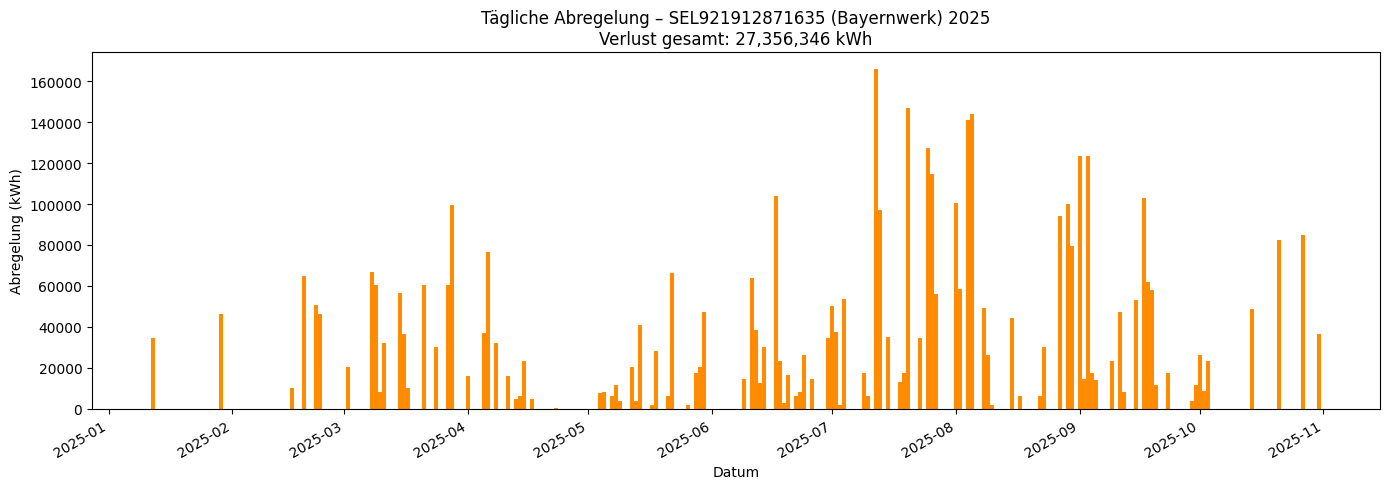

C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))
C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))


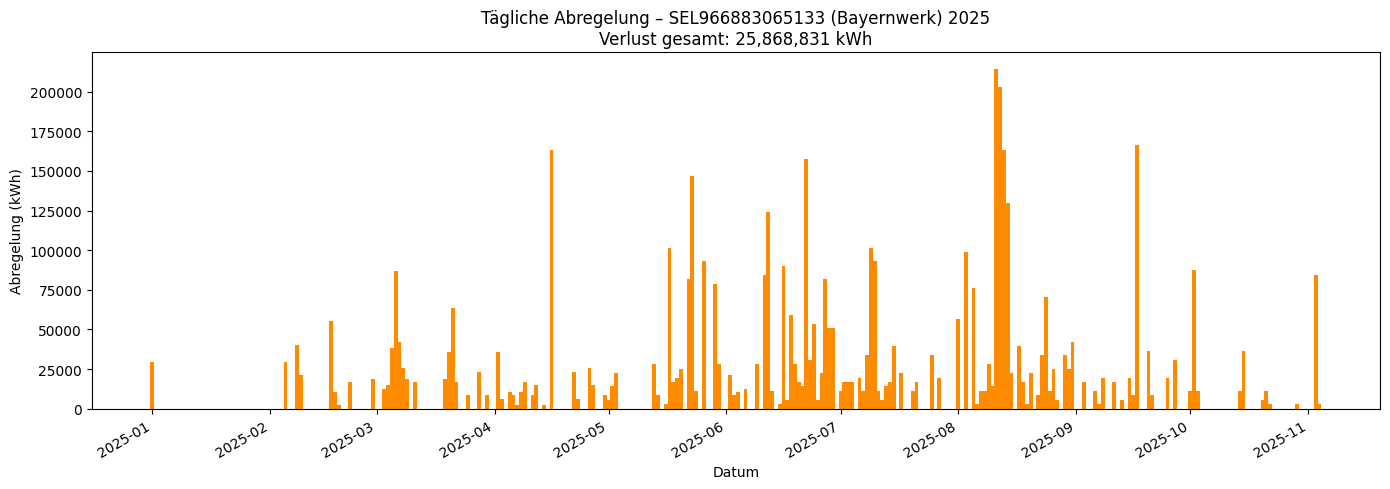

C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))
C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))


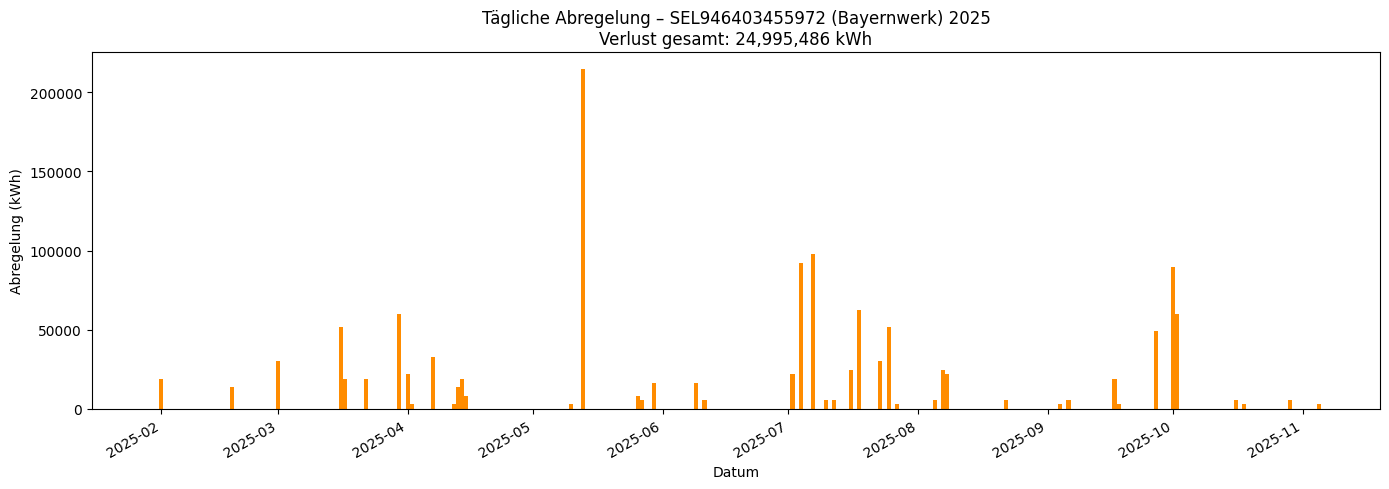

C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))
C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))


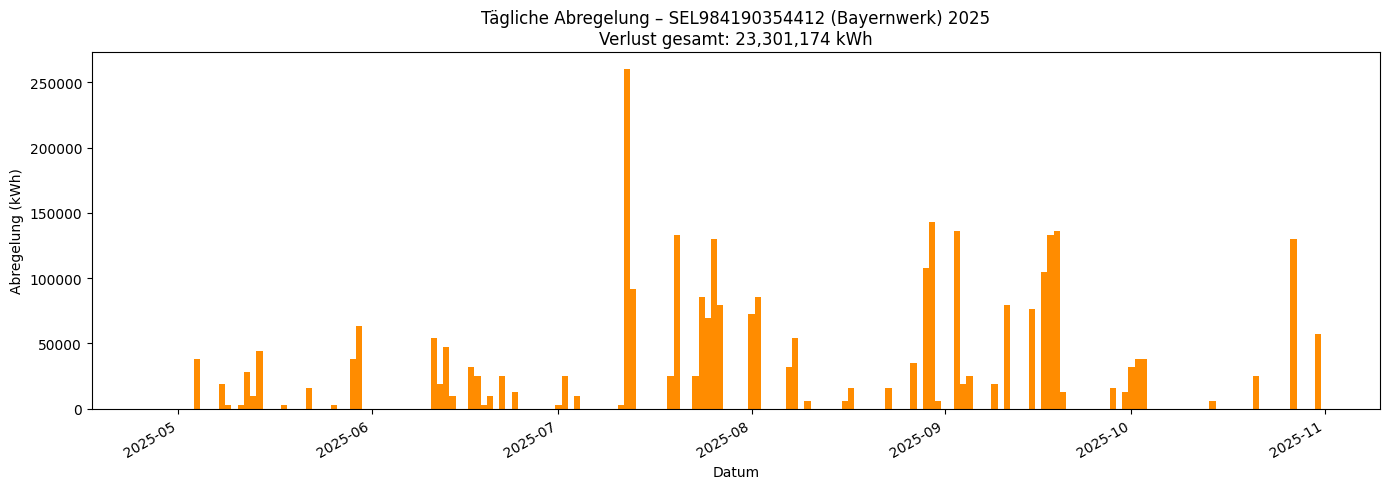

C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))
C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))


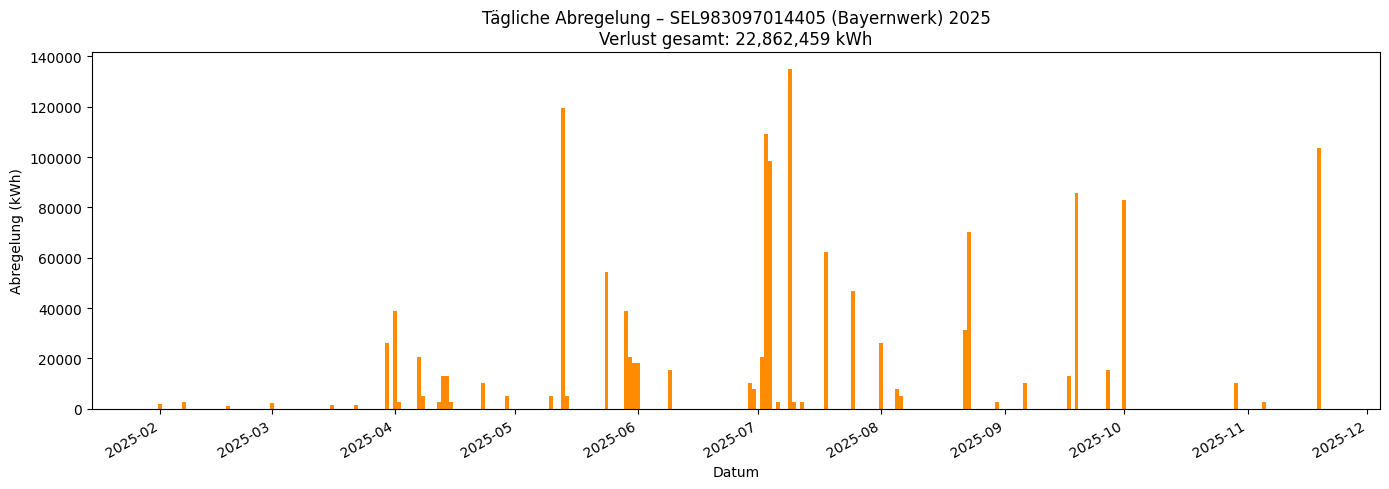

C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))
C:\Users\user\AppData\Local\Temp\ipykernel_30188\4059827320.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_na = pd.read_sql(query, conn, params=(netzanschluss,))


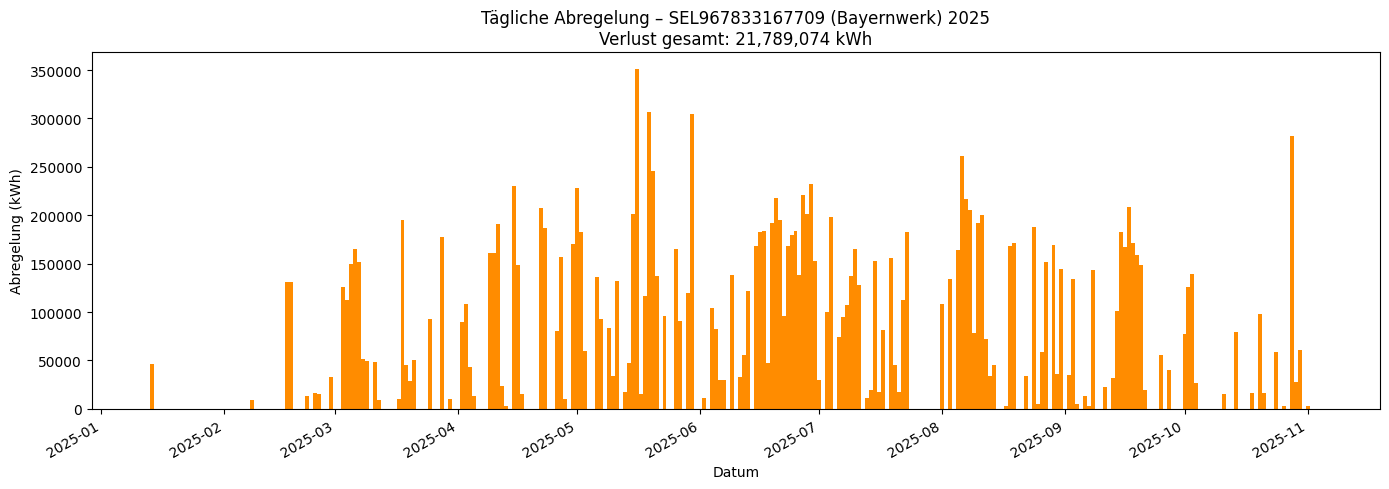

In [26]:
conn = psycopg.connect(
    dbname="redispatch_losses",
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    sslmode="require"
)

# Top 6 Netzanschlüsse Bayernwerk nach Verlust
query_top = """
    SELECT
        netzanschluss,
        SUM(verlust) AS verlust_kwh_gesamt
    FROM redispatch.redispatch_eeg_bayernwerk
    WHERE verlust IS NOT NULL
      AND netzanschluss IS NOT NULL
    GROUP BY netzanschluss
    ORDER BY verlust_kwh_gesamt DESC
    LIMIT 6
"""
df_top_bw = pd.read_sql(query_top, conn)
display(df_top_bw)

top_netzanschluesse = df_top_bw["netzanschluss"].tolist()

# Für jeden Netzanschluss: tägliche Abregelung (Wind + Solar)
for netzanschluss in top_netzanschluesse:
    verlust_gesamt = df_top_bw.loc[
        df_top_bw["netzanschluss"] == netzanschluss, "verlust_kwh_gesamt"
    ].iloc[0]

    dfs = {}
    for typ in ["wind", "solar"]:
        dwd_table = f"dwd.{typ}_bayernwerk_2025_interpolated"
        query = f"""
            SELECT 
                d.timestamp,
                SUM(d.abregelung) AS abregelung_kwh
            FROM {dwd_table} d
            JOIN redispatch.redispatch_eeg_bayernwerk r 
                ON d.eventnummer = r.eventnummer
            WHERE r.netzanschluss = %s
            GROUP BY d.timestamp
            ORDER BY d.timestamp
        """
        df_na = pd.read_sql(query, conn, params=(netzanschluss,))
        if not df_na.empty:
            dfs[typ.title()] = df_na

    if not dfs:
        print(f"Keine Abregelungsdaten für {netzanschluss}")
        continue

    # Wind + Solar zusammenführen und täglich aggregieren
    df_combined = pd.concat(dfs.values()).groupby("timestamp")["abregelung_kwh"].sum().reset_index()
    df_daily = df_combined.groupby(df_combined["timestamp"].dt.date)["abregelung_kwh"].sum().reset_index()
    df_daily.columns = ["tag", "abregelung_kwh"]

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(df_daily["tag"], df_daily["abregelung_kwh"], width=1, color="darkorange")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Abregelung (kWh)")
    ax.set_title(
        f"Tägliche Abregelung – {netzanschluss} (Bayernwerk) 2025"
        f"\nVerlust gesamt: {verlust_gesamt:,.0f} kWh"
    )
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

conn.close()

## Vertikales Windprofil nach Hellmann für verschiedene Rauigkeiten


Gespeichert: C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\wind_profile_roughness.png


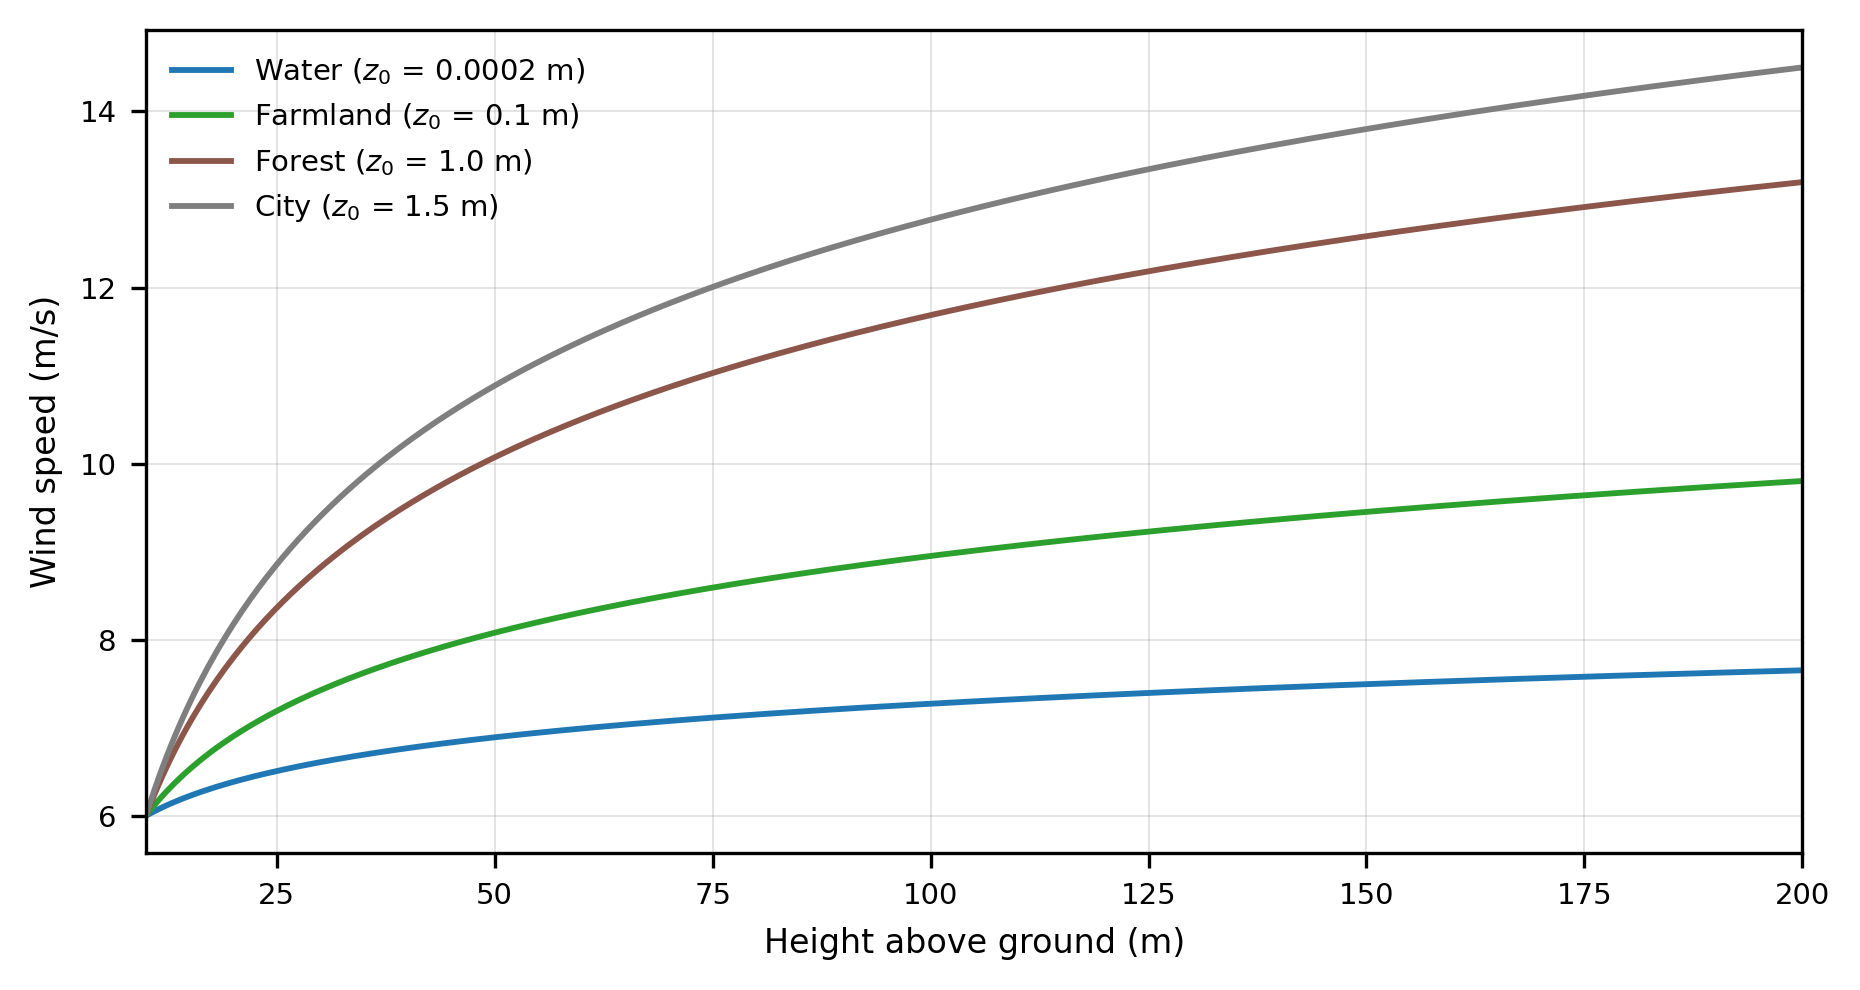

In [3]:
import numpy as np
import matplotlib.pyplot as plt

V_REF = 6.0   # reference wind speed [m/s]
H_REF = 10.0  # reference measurement height [m]

surfaces = {
    "Water": (0.0002, "#1f77b4"),
    "Farmland": (0.1, "#2ca02c"),
    "Forest": (1.0, "#8c564b"),
    "City": (1.5, "#7f7f7f"),
}

heights = np.linspace(H_REF, 200, 400)

# Figure sized for the A4 text width (16 cm) so it can be embedded without rescaling
fig, ax = plt.subplots(figsize=(6.3, 3.4), dpi=300)

for label, (z0, color) in surfaces.items():
    alpha = 1.0 / np.log(np.sqrt(heights * H_REF) / z0)
    v = V_REF * (heights / H_REF) ** alpha
    ax.plot(heights, v, color=color, linewidth=1.4, label=f"{label} ($z_0$ = {z0} m)")

ax.set_xlabel("Height above ground (m)", fontsize=8)
ax.set_ylabel("Wind speed (m/s)", fontsize=8)
ax.tick_params(axis="both", labelsize=7)
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.grid(True, linewidth=0.4, alpha=0.4)
ax.margins(x=0)
plt.tight_layout()

output_path = r"C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\wind_profile_roughness.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Gespeichert: {output_path}")
plt.show()


## Generische Leistungskurve der WEA (kubisches Modell)

Gespeichert: C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\wind_power_curve.png


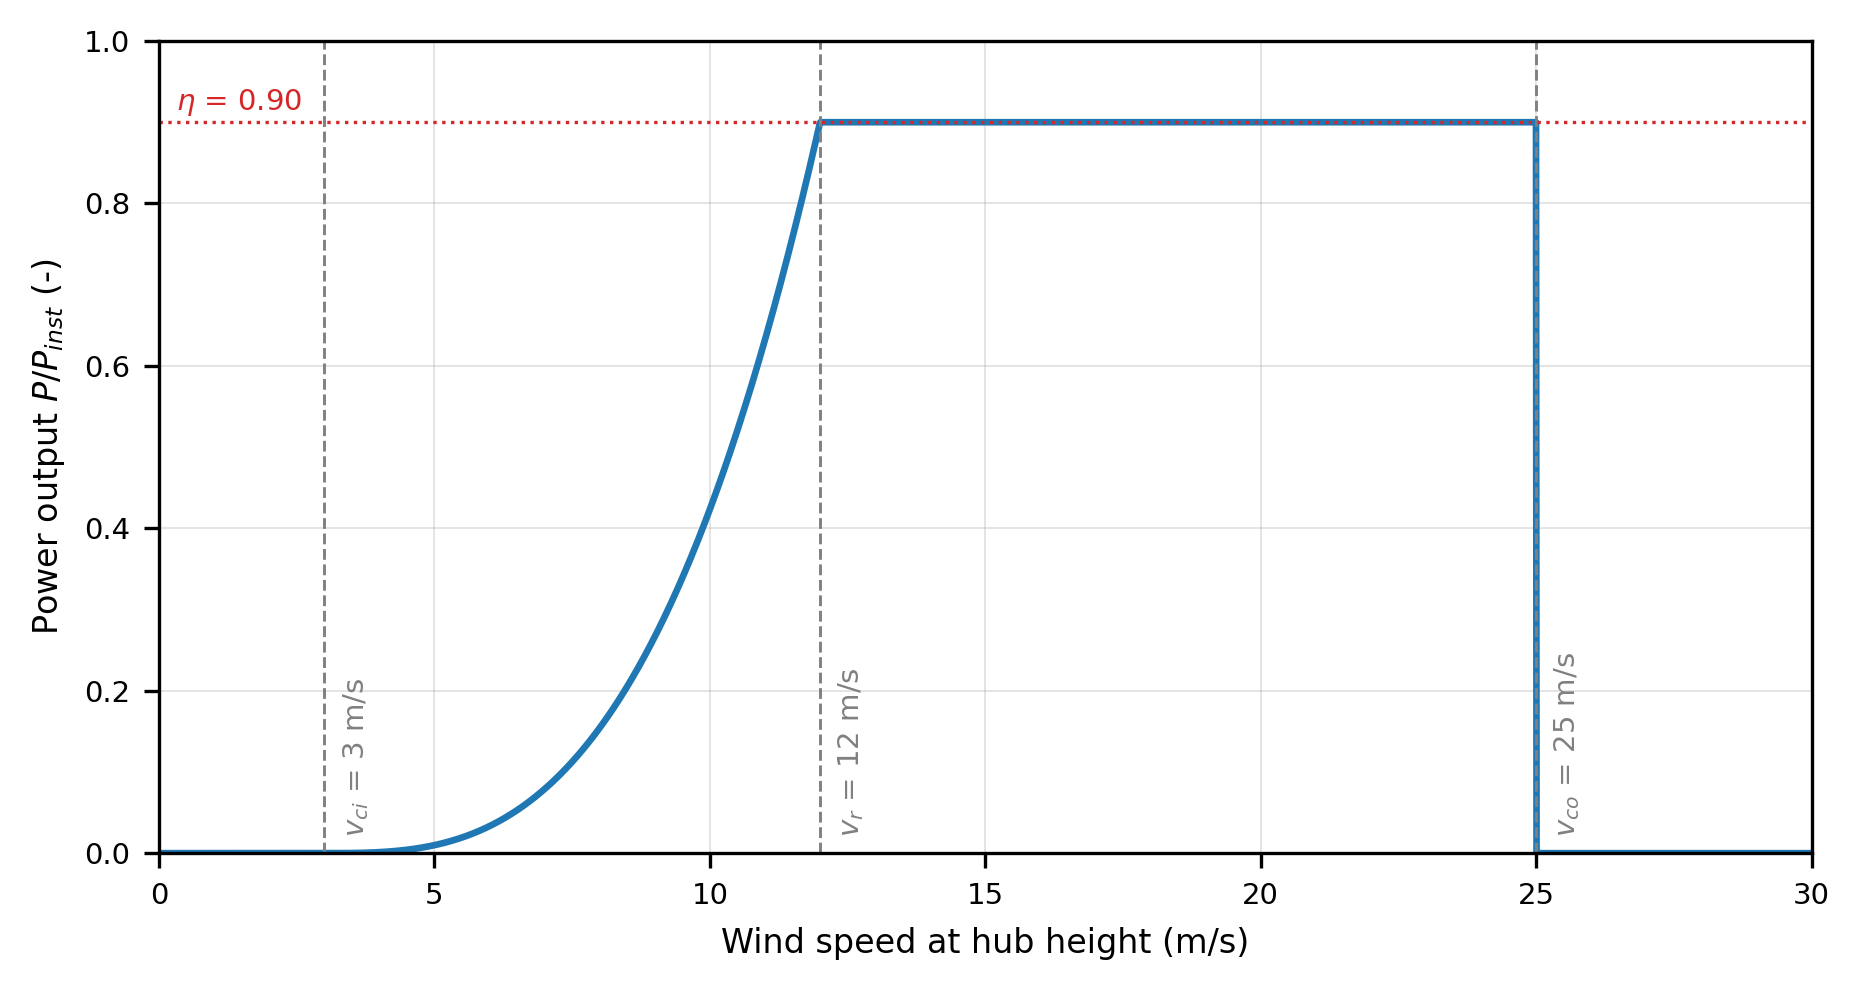

In [5]:
import numpy as np
import matplotlib.pyplot as plt

V_CI = 3.0    # cut-in wind speed [m/s]
V_R = 12.0    # rated wind speed [m/s]
V_CO = 25.0   # cut-out wind speed [m/s]
ETA = 0.90    # system efficiency [-]

v = np.linspace(0, 30, 3000)
p = np.where(
    (v >= V_CI) & (v <= V_R),
    ETA * ((v - V_CI) / (V_R - V_CI)) ** 3,
    np.where((v > V_R) & (v <= V_CO), ETA, 0.0),
)

# Figure sized for the A4 text width (16 cm) so it can be embedded without rescaling
fig, ax = plt.subplots(figsize=(6.3, 3.4), dpi=300)
ax.plot(v, p, color="#1f77b4", linewidth=1.6)

for x, name in [(V_CI, "$v_{ci}$ = 3 m/s"), (V_R, "$v_{r}$ = 12 m/s"), (V_CO, "$v_{co}$ = 25 m/s")]:
    ax.axvline(x, color="grey", linestyle="--", linewidth=0.7)
    ax.text(x + 0.3, 0.02, name, fontsize=7, rotation=90, va="bottom", color="grey")

ax.axhline(ETA, color="#d62728", linestyle=":", linewidth=0.8)
ax.text(0.3, ETA + 0.015, r"$\eta$ = 0.90", fontsize=7, color="#d62728")

ax.set_xlabel("Wind speed at hub height (m/s)", fontsize=8)
ax.set_ylabel("Power output $P/P_{inst}$ (-)", fontsize=8)
ax.tick_params(axis="both", labelsize=7)
ax.grid(True, linewidth=0.4, alpha=0.4)
ax.set_xlim(0, 30)
ax.set_ylim(0, 1.0)
plt.tight_layout()

output_path = r"C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\wind_power_curve.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Gespeichert: {output_path}")
plt.show()

## Beispiel: Ertragsberechnung PV (120 kWp) über 2 Stunden in 10-min-Intervallen

Gespeichert: C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\PV_10min_summerday_south_germany_no_curtailment.png
Summe über 2 Stunden: 173.0 kWh


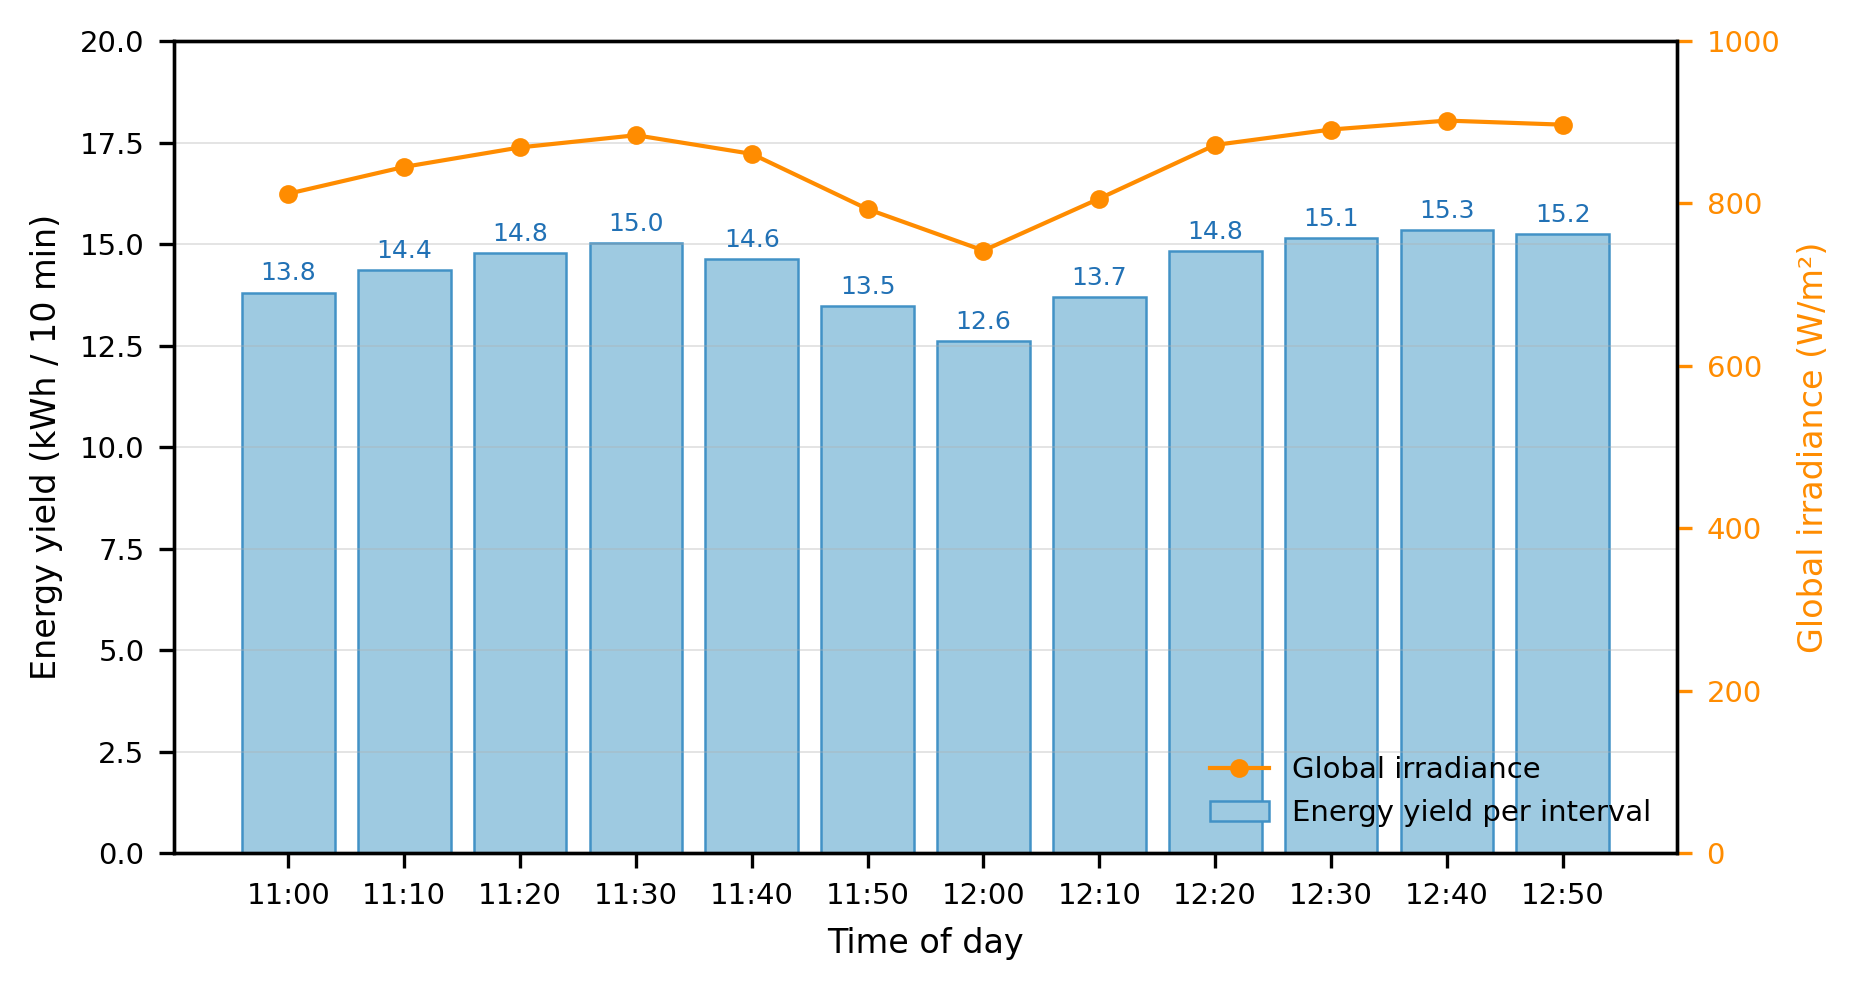

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

P_INST = 120.0   # installed capacity [kWp]
PR = 0.85        # performance ratio [-]
DT = 1 / 6       # interval length [h]

labels = [f"{11 + i // 6}:{(i % 6) * 10:02d}" for i in range(12)]
# Illustrative 10-min global irradiance, clear summer day with light cloud passage
irradiance = np.array([812, 845, 869, 884, 861, 793, 742, 806, 872, 891, 902, 897], dtype=float)

power = np.minimum(P_INST * PR * (irradiance / 1000), P_INST)
energy = power * DT

# Figure sized for the A4 text width (16 cm) so it can be embedded without rescaling
fig, ax = plt.subplots(figsize=(6.3, 3.4), dpi=300)

ax.bar(labels, energy, color="#9ecae1", edgecolor="#4292c6", linewidth=0.6,
       label="Energy yield per interval")
ax.set_xlabel("Time of day", fontsize=8)
ax.set_ylabel("Energy yield (kWh / 10 min)", fontsize=8)
ax.tick_params(axis="both", labelsize=7)
ax.set_ylim(0, 20)
ax.grid(True, axis="y", linewidth=0.4, alpha=0.4)

for x, e in zip(labels, energy):
    ax.text(x, e + 0.3, f"{e:.1f}", ha="center", fontsize=6, color="#2171b5")

ax2 = ax.twinx()
ax2.plot(labels, irradiance, color="darkorange", linewidth=1.0, marker="o", markersize=3.5,
         label="Global irradiance")
ax2.set_ylabel("Global irradiance (W/m²)", fontsize=8, color="darkorange")
ax2.tick_params(axis="y", labelsize=7, colors="darkorange")
ax2.set_ylim(0, 1000)

handles = ax2.get_lines() + ax.containers[0:1]
ax.legend(handles, ["Global irradiance", "Energy yield per interval"],
          fontsize=7, frameon=False, loc="lower right")
plt.tight_layout()

output_path = r"C:\Users\user\Projects\Documents\Desktop\MA - BESS\Code\MA\07_analysis\PV_10min_summerday_south_germany_no_curtailment.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Gespeichert: {output_path}")
print(f"Summe über 2 Stunden: {energy.sum():.1f} kWh")
plt.show()